# Домашнее задание 4.2

Основано на наработках с лабы 4.2

Ячейки с заданиями расположены после повтора блоков с лабы

Мухамедшина Сафина, DS-01

In [ ]:
# @title 1. Подготовка среды

!pip install pyspark -q

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.functions import (
    col, count, sum, avg, min, max,
    countDistinct, approx_count_distinct,
    lower, upper, trim,
    to_date, to_timestamp,
    try_to_timestamp,
    coalesce, when,
    broadcast, regexp_replace
)
from pyspark.sql.types import *
from pyspark.sql.window import Window

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os
import glob
import zipfile
import time
from datetime import datetime
from scipy import stats

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
pd.set_option('future.no_silent_downcasting', True)

SEED = 42
np.random.seed(SEED)

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("Среда подготовлена")
print(f"Pandas: {pd.__version__}, NumPy: {np.__version__}")

Среда подготовлена
Pandas: 2.2.3, NumPy: 2.1.3


In [ ]:
# @title 2. Настройка SparkSession

spark = SparkSession.builder \
    .appName("BigDataAnalytics_Practice4_2") \
    .config("spark.sql.adaptive.enabled", "true") \
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true") \
    .config("spark.sql.shuffle.partitions", "200") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")

print("Spark настроен")
print(f"Spark version: {spark.version}")
print(f"Adaptive Query Execution: {spark.conf.get('spark.sql.adaptive.enabled')}")
print(f"Shuffle partitions: {spark.conf.get('spark.sql.shuffle.partitions')}")

Spark настроен
Spark version: 4.0.4
Adaptive Query Execution: true
Shuffle partitions: 200


In [ ]:
# @title 3. Монтирование Google Drive и разархивация

from google.colab import drive
drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/out.zip'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('/content/')
    print("Данные разархивированы")
else:
    print("Файл не найден")

Mounted at /content/drive
Данные разархивированы


In [ ]:
# @title Задание 1. Профилирование: метрики качества

print("="*60)
print("ЗАДАНИЕ 1. ПРОФИЛИРОВАНИЕ: МЕТРИКИ КАЧЕСТВА")
print("="*60)

DATA_PATH = '/content/out'

# ============================================================
# Загрузка данных
# ============================================================
cdr_files = sorted(glob.glob(os.path.join(DATA_PATH, 'raw', 'cdr', 'dt=*', 'cdr.csv')))
df_cdr = pd.concat([pd.read_csv(f) for f in cdr_files[:3]], ignore_index=True)

print(f"CDR загружено: {len(df_cdr):,} записей")
print(f"Колонок: {len(df_cdr.columns)}")
print()

ЗАДАНИЕ 1. ПРОФИЛИРОВАНИЕ: МЕТРИКИ КАЧЕСТВА
CDR загружено: 320,203 записей
Колонок: 15



In [ ]:
df_cdr.head()

,record_id,event_ts,ingest_ts,subscriber_key,service_type,direction,duration_sec,bytes_up,bytes_down,node_id,region_id,tariff_id,roaming_flag,partner_code,charge
0,72314,2025-10-01 08:03:26,2025-10-02 06:34:51,SUB000097176,data,out,0,92698,43400,ND001272,1,T33,False,NaN,0.06
1,52727,2025-10-01 13:35:30,2025-10-01 13:38:48,SUB000149213,data,out,0,368502,1086455,ND003885,53,T38,False,NaN,0.61
2,5733,2025-10-01 15:48:22,2025-10-01 21:08:37,SUB000013555,sms,out,0,0,0,ND002930,3,T15,False,NaN,1.90
3,2268,2025-10-01 09:18:10,2025-10-01 09:22:56,SUB000044975,voice,in,145,0,0,ND014719,3,T27,False,NaN,1.74
4,47311,2025-10-01 00:15:52,2025-10-01 00:19:29,SUB000008882,data,in,0,221,90963,ND000217,12,T31,False,NaN,0.04


In [ ]:
df_cdr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320203 entries, 0 to 320202
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   record_id       320203 non-null  int64  
 1   event_ts        320203 non-null  object 
 2   ingest_ts       320203 non-null  object 
 3   subscriber_key  319557 non-null  object 
 4   service_type    320203 non-null  object 
 5   direction       320203 non-null  object 
 6   duration_sec    320203 non-null  int64  
 7   bytes_up        320203 non-null  int64  
 8   bytes_down      320203 non-null  int64  
 9   node_id         304213 non-null  object 
 10  region_id       320203 non-null  int64  
 11  tariff_id       320203 non-null  object 
 12  roaming_flag    320203 non-null  bool   
 13  partner_code    12067 non-null   object 
 14  charge          320203 non-null  float64
dtypes: bool(1), float64(1), int64(5), object(8)
memory usage: 34.5+ MB


In [ ]:
df_cdr.notna().sum()

,0
record_id,320203
event_ts,320203
ingest_ts,320203
subscriber_key,319557
service_type,320203
direction,320203
duration_sec,320203
bytes_up,320203
bytes_down,320203
node_id,304213


In [ ]:
# ============================================================
# TODO 1.1: Метрика «Полнота» (Completeness)
# ============================================================
# Подсказка: используйте df.notna().sum() для количества заполненных
# Подсказка: разделите на len(df) и умножьте на 100 для процентов
# Подсказка: создайте DataFrame с колонками: column, filled, total, completeness_pct
# Подсказка: отсортируйте по completeness_pct по возрастанию
df_completeness = pd.DataFrame({'column' : df_cdr.columns,
                   'filled' : df_cdr.notna().sum(),
                   'total' : len(df_cdr),
                   'completeness_pct' : df_cdr.notna().sum()/len(df_cdr) * 100
                   })

df_completeness.sort_values(by='completeness_pct')

print("--- МЕТРИКА 1: ПОЛНОТА ---")
print("Доля заполненных значений в каждой колонке:")
print(df_completeness['completeness_pct'])

# Ваш код здесь


print()

# ============================================================
# TODO 1.2: Метрика «Уникальность» (Uniqueness)
# ============================================================
# Подсказка: используйте df.nunique() для количества уникальных
# Подсказка: разделите на len(df) и умножьте на 100 для процентов
# Подсказка: создайте DataFrame с колонками: column, unique, total, uniqueness_pct
# Подсказка: отсортируйте по uniqueness_pct по возрастанию

print("--- МЕТРИКА 2: УНИКАЛЬНОСТЬ ---")
print("Доля уникальных значений в каждой колонке:")
print()

# Ваш код здесь
uniqueness_df = pd.DataFrame({'column' : df_cdr.columns,
                   'unique' : df_cdr.nunique(),
                   'total' : len(df_cdr),
                   'uniqueness_pct' : df_cdr.nunique()/len(df_cdr) * 100
                   })

uniqueness_df.sort_values(by='uniqueness_pct')


print(uniqueness_df['uniqueness_pct'])

# ============================================================
# TODO 1.3: Метрика «Согласованность» (Consistency)
# ============================================================
# Подсказка: проверьте уникальные значения в service_type и direction
# Подсказка: используйте df['service_type'].value_counts()
# Подсказка: используйте df['direction'].value_counts()

print("--- МЕТРИКА 3: СОГЛАСОВАННОСТЬ ---")
print("Проверка форматов и справочников:")
print()

# Ваш код здесь
service_consistency = df_cdr['service_type'].value_counts()
direction_consistency = df_cdr['direction'].value_counts()
df_consistency = pd.DataFrame({'column' : ['service_type', 'direction'],
                               'consistency' : [service_consistency,direction_consistency]})


print(df_consistency['consistency'])

# ============================================================
# TODO 1.4: Метрика «Точность» (Accuracy)
# ============================================================
# Подсказка: проверьте отрицательные значения в duration_sec, bytes_down, charge
# Подсказка: используйте (df['duration_sec'] < 0).sum()
# Подсказка: выведите количество и процент

print("--- МЕТРИКА 4: ТОЧНОСТЬ ---")
print("Проверка допустимых значений:")
print()

# Ваш код здесь

cols = ['duration_sec', 'bytes_down', 'charge']
duration_acc = (df_cdr['duration_sec'] < 0).sum()
bytes_acc = (df_cdr['bytes_down'] < 0).sum()
charge_acc = (df_cdr['charge'] < 0).sum()

accuracy_df = pd.DataFrame({'column' : cols,
                            'accuracy_cnt' : [duration_acc, bytes_acc, charge_acc],
                            'accuracy_perc' : [duration_acc/len(df_cdr['duration_sec'])*100, bytes_acc / len(df_cdr['bytes_down'])*100, charge_acc/len(df_cdr['charge'])*100]


})


print(accuracy_df['accuracy_cnt'])

# ============================================================
# TODO 1.5: Метрика «Актуальность» (Timeliness)
# ============================================================
# Подсказка: парсите event_ts через pd.to_datetime(format='mixed', errors='coerce')
# Подсказка: выведите min и max
# Подсказка: вычислите период в днях

print("--- МЕТРИКА 5: АКТУАЛЬНОСТЬ ---")
print("Проверка временного периода:")
print()

# Ваш код здесь
event_dates = pd.to_datetime(df_cdr['event_ts'], format='mixed', errors='coerce')
min_date, max_date = event_dates.min(), event_dates.max()
period_days = (max_date - min_date).days if pd.notna(min_date) and pd.notna(max_date) else 0
print(f' min event_ts: {min_date}')
print(f' max event_ts: {max_date}')
print(f' Период: {period_days} дней')
print(f' Не удалось разобрать дат: {event_dates.isna().sum():,}')


print()

# ============================================================
# Сохранение отчёта
# ============================================================
# Подсказка: создайте строку с отчётом
# Подсказка: сохраните в profiling_metrics_report.md
report_1 = f"""# Отчет по качеству данных (Профилирование)

## 1. Полнота (Completeness)
{df_completeness.to_markdown(index=False)}

## 2. Уникальность (Uniqueness)
{uniqueness_df.to_markdown(index=False)}

## 3. Согласованность (Consistency)
- service_type: {df_cdr['service_type'].value_counts().to_dict()}
- direction: {df_cdr['direction'].value_counts().to_dict()}

## 4. Точность (Accuracy)
- duration_sec (< 0): {(df_cdr['duration_sec'] < 0).sum()}
- bytes_down (< 0): {(df_cdr['bytes_down'] < 0).sum()}
- charge (< 0): {(df_cdr['charge'] < 0).sum()}

## 5. Актуальность (Timeliness)
- Период с {min_date} по {max_date} {(max_date - min_date).days} дней
"""
with open('profiling_metrics_report.md', 'w', encoding='utf-8') as f:
  f.write(report_1)
print("Отчёт сохранён: profiling_metrics_report.md")


# ============================================================
# Вывод
# ============================================================
print("="*60)
print("ВЫВОД")
print("="*60)
print("""
Метрики качества данных:
1. Полнота — доля заполненных значений
2. Уникальность — доля уникальных значений
3. Согласованность — соответствие форматов и справочников
4. Точность — соответствие допустимым значениям
5. Актуальность — соответствие временному периоду

Важно: не все пропуски — дефект. Некоторые — особенность источника.
""")

--- МЕТРИКА 1: ПОЛНОТА ---
Доля заполненных значений в каждой колонке:
record_id        100.00
event_ts         100.00
ingest_ts        100.00
subscriber_key    99.80
service_type     100.00
direction        100.00
duration_sec     100.00
bytes_up         100.00
bytes_down       100.00
node_id           95.01
region_id        100.00
tariff_id        100.00
roaming_flag     100.00
partner_code       3.77
charge           100.00
Name: completeness_pct, dtype: float64

--- МЕТРИКА 2: УНИКАЛЬНОСТЬ ---
Доля уникальных значений в каждой колонке:

record_id        99.48
event_ts         50.59
ingest_ts        51.42
subscriber_key   25.59
service_type      0.00
direction         0.00
duration_sec      0.25
bytes_up         39.11
bytes_down       50.36
node_id          12.86
region_id         0.03
tariff_id         0.02
roaming_flag      0.00
partner_code      0.00
charge            0.48
Name: uniqueness_pct, dtype: float64
--- МЕТРИКА 3: СОГЛАСОВАННОСТЬ ---
Проверка форматов и справочников:

0

In [ ]:
# @title Задание 2. Очистка: стратегии обработки

print("="*60)
print("ЗАДАНИЕ 2. ОЧИСТКА: СТРАТЕГИИ ОБРАБОТКИ")
print("="*60)

df_clean = df_cdr.copy()
initial_rows = len(df_clean)

# ============================================================
# TODO 2.1: Стратегия «Удаление дубликатов»
# ============================================================
# Подсказка: используйте df.duplicated().sum() для подсчёта
# Подсказка: используйте df.drop_duplicates() для удаления
# Подсказка: сохраните количество удалённых дубликатов

print("--- СТРАТЕГИЯ 1: УДАЛЕНИЕ ДУБЛИКАТОВ ---")
print("Правило: полные дубликаты — удаляем")
print()

# Ваш код здесь
dup_count = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()
print(f"Удалено дубликатов: {dup_count:,}")
print(f"Записей после: {len(df_clean):,}\n")


print()

# ============================================================
# TODO 2.2: Стратегия «Обработка пропусков»
# ============================================================
# Подсказка: subscriber_key — удалить (df.dropna(subset=['subscriber_key']))
# Подсказка: node_id — заполнить 'unknown' (df['node_id'].fillna('unknown'))
# Подсказка: partner_code — заполнить 'no_partner' (df['partner_code'].fillna('no_partner'))
# Подсказка: сохраните количество обработанных записей

print("--- СТРАТЕГИЯ 2: ОБРАБОТКА ПРОПУСКОВ ---")
print("Правило: выбор стратегии зависит от природы данных")
print()

# Ваш код здесь
sub_missing = df_clean['subscriber_key'].isna().sum()
df_clean = df_clean.dropna(subset=['subscriber_key'])

node_missing = df_clean['node_id'].isna().sum()
df_clean['node_id'] = df_clean['node_id'].fillna('unknown')

partner_missing = df_clean['partner_code'].isna().sum()
df_clean['partner_code'] = df_clean['partner_code'].fillna('no_partner')

print(f"subscriber_key: удалено {sub_missing:,} записей (ключевая колонка)")
print(f"node_id: заполнено {node_missing:,} (особенность источника)")
print(f"partner_code: заполнено {partner_missing:,} (особенность источника)\n")


print()

# ============================================================
# TODO 2.3: Стратегия «Обработка отрицательных значений»
# ============================================================
# Подсказка: замените отрицательные значения на 0
# Подсказка: df.loc[df['duration_sec'] < 0, 'duration_sec'] = 0
# Подсказка: df.loc[df['bytes_down'] < 0, 'bytes_down'] = 0

print("--- СТРАТЕГИЯ 3: ОБРАБОТКА ОТРИЦАТЕЛЬНЫХ ЗНАЧЕНИЙ ---")
print("Правило: отрицательные значения — дефект, заменяем на 0")
print()

# Ваш код здесь
dur_neg = (df_clean['duration_sec'] < 0).sum()
bytes_neg = (df_clean['bytes_down'] < 0).sum()

df_clean.loc[df_clean['duration_sec'] < 0, 'duration_sec'] = 0
df_clean.loc[df_clean['bytes_down'] < 0, 'bytes_down'] = 0

print(f"duration_sec: исправлено {dur_neg:,}")
print(f"bytes_down: исправлено {bytes_neg:,}\n")


print()

# ============================================================
# TODO 2.4: Стратегия «Обработка выбросов»
# ============================================================
# Подсказка: duration_sec — обрезать по 99-му процентилю
# Подсказка: q99 = df['duration_sec'].quantile(0.99)
# Подсказка: df.loc[df['duration_sec'] > q99, 'duration_sec'] = q99
# Подсказка: charge — аналогично
# Подсказка: bytes_down — логарифмирование (np.log1p)

print("--- СТРАТЕГИЯ 4: ОБРАБОТКА ВЫБРОСОВ ---")
print("Правило: процентили для скошенного распределения")
print()

# Ваш код здесь
q99_dur = df_clean['duration_sec'].quantile(0.99)
dur_outliers = (df_clean['duration_sec'] > q99_dur).sum()
df_clean.loc[df_clean['duration_sec'] > q99_dur, 'duration_sec'] = q99_dur

q99_charge = df_clean['charge'].quantile(0.99)
charge_outliers = (df_clean['charge'] > q99_charge).sum()
df_clean.loc[df_clean['charge'] > q99_charge, 'charge'] = q99_charge

df_clean['log_bytes_down'] = np.log1p(df_clean['bytes_down'])

print(f"duration_sec: обрезано {dur_outliers:,} (>{int(q99_dur)})")
print(f"charge: обрезано {charge_outliers:,} (>{int(q99_charge)})")
print("bytes_down: создан признак log_bytes_down\n")


# ============================================================
# TODO 2.5: Стратегия «Приведение типов и унификация»
# ============================================================
# Подсказка: event_ts и ingest_ts — pd.to_datetime(format='mixed', errors='coerce')
# Подсказка: service_type и direction — .astype(str).str.lower().str.strip()

print("--- СТРАТЕГИЯ 5: ПРИВЕДЕНИЕ ТИПОВ И УНИФИКАЦИЯ ---")
print()

# Ваш код здесь
df_clean['event_ts'] = pd.to_datetime(df_clean['event_ts'], format='mixed', dayfirst=True, errors='coerce')
df_clean['ingest_ts'] = pd.to_datetime(df_clean['ingest_ts'], errors='coerce')
df_clean['service_type'] = df_clean['service_type'].astype(str).str.lower().str.strip()
df_clean['direction'] = df_clean['direction'].astype(str).str.lower().str.strip()
print(f"Не распознано дат: {df_clean['event_ts'].isna().sum()}")
print(df_clean['service_type'].value_counts().to_string())


# ============================================================
# Сохранение
# ============================================================
# Подсказка: os.makedirs('/content/processed', exist_ok=True)
# Подсказка: df_clean.to_parquet('/content/processed/cdr_clean.parquet', index=False)

# Ваш код здесь
os.makedirs('/content/processed', exist_ok=True)
df_clean.to_parquet('/content/processed/cdr_clean.parquet', index=False)
print("Очищенные данные сохранены: /content/processed/cdr_clean.parquet")


# ============================================================
# Вывод
# ============================================================
print("="*60)
print("ВЫВОД")
print("="*60)
print("""
Стратегии обработки:
1. Дубликаты: полные — удаляем
2. Пропуски: удаление для ключевых, заполнение для особенностей
3. Отрицательные: заменяем на 0
4. Выбросы: обрезаем по 99-му процентилю
5. Типы: приводим к единому формату

Важно: выбор стратегии зависит от природы данных.
""")

ЗАДАНИЕ 2. ОЧИСТКА: СТРАТЕГИИ ОБРАБОТКИ
--- СТРАТЕГИЯ 1: УДАЛЕНИЕ ДУБЛИКАТОВ ---
Правило: полные дубликаты — удаляем

Удалено дубликатов: 1,655
Записей после: 318,548


--- СТРАТЕГИЯ 2: ОБРАБОТКА ПРОПУСКОВ ---
Правило: выбор стратегии зависит от природы данных

subscriber_key: удалено 643 записей (ключевая колонка)
node_id: заполнено 15,903 (особенность источника)
partner_code: заполнено 305,916 (особенность источника)


--- СТРАТЕГИЯ 3: ОБРАБОТКА ОТРИЦАТЕЛЬНЫХ ЗНАЧЕНИЙ ---
Правило: отрицательные значения — дефект, заменяем на 0

duration_sec: исправлено 937
bytes_down: исправлено 936


--- СТРАТЕГИЯ 4: ОБРАБОТКА ВЫБРОСОВ ---
Правило: процентили для скошенного распределения

duration_sec: обрезано 3,160 (>324)
charge: обрезано 3,170 (>5)
bytes_down: создан признак log_bytes_down

--- СТРАТЕГИЯ 5: ПРИВЕДЕНИЕ ТИПОВ И УНИФИКАЦИЯ ---

Не распознано дат: 0
service_type
data     181243
voice     95496
sms       41166
Очищенные данные сохранены: /content/processed/cdr_clean.parquet
ВЫВОД

Стр

In [ ]:
# @title Задание 3. Интеграция: ключи и соединения

print("="*60)
print("ЗАДАНИЕ 3. ИНТЕГРАЦИЯ: КЛЮЧИ И СОЕДИНЕНИЯ")
print("="*60)

# ============================================================
# Загрузка tickets
# ============================================================
ticket_files = sorted(glob.glob(os.path.join(DATA_PATH, 'raw', 'tickets', 'dt=*', 'tickets.csv')))
df_tickets = pd.concat([pd.read_csv(f) for f in ticket_files[:3]], ignore_index=True)

print(f"Tickets загружено: {len(df_tickets):,} записей")
print()

# ============================================================
# TODO 3.1: Проблема «один ко многим»
# ============================================================
# Подсказка: посчитайте, что будет, если соединить без агрегации
# Подсказка: len(df_clean) * len(df_tickets) — это количество дубликатов

print("--- ПРОБЛЕМА «ОДИН КО МНОГИМ» ---")
print("Если соединить CDR и tickets по subscriber_key без агрегации:")
print()

# Ваш код здесь
cdr_counts = df_clean.groupby('subscriber_key').size()
ticket_counts_by_subscriber = df_tickets.groupby('subscriber_key').size()
matched_counts = cdr_counts.to_frame('cdr').join(
ticket_counts_by_subscriber.rename('tickets'), how='inner'
)
matched_join_rows = int((matched_counts['cdr'] * matched_counts['tickets']).sum())
left_join_rows = len(df_clean) - int(matched_counts['cdr'].sum()) + matched_join_rows
print(f' CDR: {len(df_clean):,} записей')
print(f' Tickets: {len(df_tickets):,} записей')
print(f' LEFT JOIN без агрегации: {left_join_rows:,} строк')
print(f' Потенциальное декартово произведение: {len(df_clean) * len(df_tickets):,} строк')



print()

# ============================================================
# TODO 3.2: Агрегация tickets по абоненту
# ============================================================
# Подсказка: используйте groupby('subscriber_key').agg()
# Подсказка: ticket_count=('ticket_id', 'count')
# Подсказка: main_category=('category', lambda x: x.mode()[0] if len(x) > 0 else 'unknown')
# Подсказка: main_channel=('channel', lambda x: x.mode()[0] if len(x) > 0 else 'unknown')
# Подсказка: retention_contact=('retention_contact', 'max')
# Подсказка: .reset_index()

print("--- АГРЕГАЦИЯ TICKETS ---")
print()

# Ваш код здесь
tickets_agg = df_tickets.groupby('subscriber_key').agg(
    ticket_count=('ticket_id', 'count'),
    main_category=('category', lambda x: x.mode()[0] if len(x) > 0 else 'unknown'),
    main_channel=('channel', lambda x: x.mode()[0] if len(x) > 0 else 'unknown'),
    retention_contact=('retention_contact', 'max')
).reset_index()

print(f"Агрегировано tickets: {len(tickets_agg):,} абонентов")
print()


print()

# ============================================================
# TODO 3.3: Агрегация CDR по абоненту
# ============================================================
# Подсказка: используйте groupby('subscriber_key').agg()
# Признаки: total_duration, avg_duration, total_bytes, avg_bytes,
#           total_charge, avg_charge, total_calls, first_call, last_call,
#           roaming_share, unique_nodes, unique_regions,
#           main_service, main_tariff
# Подсказка: .reset_index()

print("--- АГРЕГАЦИЯ CDR ---")
print()

# Ваш код здесь
cdr_agg = df_clean.groupby('subscriber_key').agg(
    total_duration=('duration_sec', 'sum'),
    avg_duration=('duration_sec', 'mean'),
    total_bytes=('bytes_down', 'sum'),
    avg_bytes=('bytes_down', 'mean'),
    total_charge=('charge', 'sum'),
    avg_charge=('charge', 'mean'),
    total_calls=('record_id', 'count'),
    first_call=('event_ts', 'min'),
    last_call=('event_ts', 'max'),
    roaming_share=('roaming_flag', 'mean'),
    unique_nodes=('node_id', 'nunique'),
    unique_regions=('region_id', 'nunique'),
    main_service=('service_type', lambda x: x.mode()[0] if len(x) > 0 else 'unknown'),
    main_tariff=('tariff_id', lambda x: x.mode()[0] if len(x) > 0 else 'unknown')
).reset_index()

print(f"Агрегировано CDR: {len(cdr_agg):,} абонентов")
print()


print()

# ============================================================
# TODO 3.4: Соединение с LEFT JOIN
# ============================================================
# Подсказка: используйте cdr_agg.merge(tickets_agg, on='subscriber_key', how='left')
# Подсказка: заполните пропуски после соединения
# Подсказка: ticket_count.fillna(0), main_category.fillna('no_tickets')
# Подсказка: main_channel.fillna('no_tickets'), retention_contact.fillna(False)

print("--- СОЕДИНЕНИЕ С LEFT JOIN ---")
print("Правило: LEFT JOIN сохраняет все записи из левой таблицы")
print()

# Ваш код здесь
df_merged = cdr_agg.merge(
    tickets_agg,
    on='subscriber_key',
    how='left'
)


print()

# ============================================================
# TODO 3.5: Загрузка telemetry
# ============================================================
# Подсказка: используйте pd.read_json(f, lines=True)
# Подсказка: путь: /content/out/raw/telemetry/dt=*/telemetry.jsonl

print("--- ЗАГРУЗКА TELEMETRY ---")
print()

# Ваш код здесь
telemetry_files = sorted(glob.glob(os.path.join(DATA_PATH, 'raw', 'telemetry', 'dt=*', 'telemetry.jsonl')))
df_telemetry = pd.concat([pd.read_json(f, lines=True) for f in telemetry_files[:3]], ignore_index=True)

print(f"Telemetry загружено: {len(df_telemetry):,} записей")
print()


print()

# ============================================================
# TODO 3.6: Агрегация telemetry по узлу
# ============================================================
# Подсказка: используйте groupby('node_id').agg()
# Признаки: avg_load, max_load, avg_error_rate, max_error_rate,
#           avg_latency, avg_temperature
# Подсказка: .reset_index()

print("--- АГРЕГАЦИЯ TELEMETRY ---")
print()

# Ваш код здесь
telemetry_agg = df_telemetry.groupby('node_id').agg(
    avg_load=('load_pct', 'mean'),
    max_load=('load_pct', 'max'),
    avg_error_rate=('error_rate', 'mean'),
    max_error_rate=('error_rate', 'max'),
    avg_latency=('latency_ms', 'mean'),
    avg_temperature=('temperature_c', 'mean')
).reset_index()

print(f"Агрегировано telemetry: {len(telemetry_agg):,} узлов")
print()


print()

# ============================================================
# TODO 3.7: Соединение с telemetry
# ============================================================
# Подсказка: получите основной узел для каждого абонента
# Подсказка: df_clean.groupby('subscriber_key')['node_id'].agg(lambda x: x.mode()[0] if len(x) > 0 else 'unknown')
# Подсказка: соедините с telemetry_agg по main_node

print("--- СОЕДИНЕНИЕ С TELEMETRY ---")
print()

# Ваш код здесь
# Получаем основной узел для каждого абонента
main_node = df_clean.groupby('subscriber_key')['node_id'].agg(
    lambda x: x.mode()[0] if len(x) > 0 else 'unknown'
).reset_index(name='main_node')

df_merged = df_merged.merge(main_node, on='subscriber_key', how='left')

# Соединяем с telemetry
df_merged = df_merged.merge(
    telemetry_agg,
    left_on='main_node',
    right_on='node_id',
    how='left'
)

print(f"CDR + Tickets + Telemetry: {len(df_merged):,} абонентов")


print()

# ============================================================
# Сохранение
# ============================================================
# Подсказка: df_merged.to_parquet('/content/processed/cdr_full.parquet', index=False)

# Ваш код здесь
os.makedirs('/content/processed', exist_ok=True)
df_merged.to_parquet('/content/processed/cdr_full.parquet', index=False)
print(f"Интегрированные данные сохранены: /content/processed/cdr_full.parquet")
print()


# ============================================================
# Вывод
# ============================================================
print("="*60)
print("ВЫВОД")
print("="*60)
print("""
Ключи соединения:
1. subscriber_key — абонент (CDR + tickets)
2. node_id — узел сети (CDR + telemetry)
3. tariff_id — тариф (CDR + справочник)
4. region_id — регион (CDR + справочник)

Проблема «один ко многим»:
- Решение: агрегация перед соединением
- Тип соединения: LEFT JOIN сохраняет все записи
""")

ЗАДАНИЕ 3. ИНТЕГРАЦИЯ: КЛЮЧИ И СОЕДИНЕНИЯ
Tickets загружено: 4,782 записей

--- ПРОБЛЕМА «ОДИН КО МНОГИМ» ---
Если соединить CDR и tickets по subscriber_key без агрегации:

 CDR: 317,905 записей
 Tickets: 4,782 записей
 LEFT JOIN без агрегации: 3,133,804 строк
 Потенциальное декартово произведение: 1,520,221,710 строк

--- АГРЕГАЦИЯ TICKETS ---

Агрегировано tickets: 3,251 абонентов


--- АГРЕГАЦИЯ CDR ---

Агрегировано CDR: 81,924 абонентов


--- СОЕДИНЕНИЕ С LEFT JOIN ---
Правило: LEFT JOIN сохраняет все записи из левой таблицы


--- ЗАГРУЗКА TELEMETRY ---

Telemetry загружено: 63,708 записей


--- АГРЕГАЦИЯ TELEMETRY ---

Агрегировано telemetry: 34,039 узлов


--- СОЕДИНЕНИЕ С TELEMETRY ---

CDR + Tickets + Telemetry: 81,924 абонентов

Интегрированные данные сохранены: /content/processed/cdr_full.parquet

ВЫВОД

Ключи соединения:
1. subscriber_key — абонент (CDR + tickets)
2. node_id — узел сети (CDR + telemetry)
3. tariff_id — тариф (CDR + справочник)
4. region_id — регион (CDR + с

In [ ]:
# @title Задание 4. Feature Engineering: методы создания

print("="*60)
print("ЗАДАНИЕ 4. FEATURE ENGINEERING: МЕТОДЫ СОЗДАНИЯ")
print("="*60)

df_feat = df_merged.copy()

# ============================================================
# TODO 4.1: Метод «Агрегация»
# ============================================================
# Подсказка: active_days = (last_call - first_call).dt.days
# Подсказка: calls_per_day = total_calls / (active_days + 1)

print("--- МЕТОД 1: АГРЕГАЦИЯ ---")
print("Вычисление суммы, среднего, медианы по группе")
print()

df_feat['active_days'] = (df_feat['last_call'] - df_feat['first_call']).dt.days
df_feat['calls_per_day'] = df_feat['total_calls'] / (df_feat['active_days'] + 1)

# Ваш код здесь


print()

# ============================================================
# TODO 4.2: Метод «Разность»
# ============================================================
# Подсказка: days_since_last_call = (pd.Timestamp.now() - pd.to_datetime(last_call)).dt.days

print("--- МЕТОД 2: РАЗНОСТЬ ---")
print("Вычисление разницы между датами или значениями")
print()

# Ваш код здесь
df_feat['days_since_last_call'] = (
pd.Timestamp.now() - pd.to_datetime(df_feat['last_call'])
).dt.days



print()

# ============================================================
# TODO 4.3: Метод «Отношение»
# ============================================================
# Подсказка: bytes_per_call = total_bytes / (total_calls + 1)
# Подсказка: charge_per_call = total_charge / (total_calls + 1)
# Подсказка: duration_per_call = total_duration / (total_calls + 1)

print("--- МЕТОД 3: ОТНОШЕНИЕ ---")
print("Вычисление доли или процента")
print()

# Ваш код здесь
df_feat['bytes_per_call'] = df_feat['total_bytes'] / (df_feat['total_calls'] + 1)
df_feat['charge_per_call'] = df_feat['total_charge'] / (df_feat['total_calls'] + 1)
df_feat['duration_per_call'] = df_feat['total_duration'] / (df_feat['total_calls'] + 1)


print()

# ============================================================
# TODO 4.4: Метод «Тренд»
# ============================================================
# Подсказка: используйте функцию calculate_trend
# def calculate_trend(group):
#     group = group.sort_values('event_ts')
#     half = len(group) // 2
#     if half == 0:
#         return 0
#     first_half = group.iloc[:half]['bytes_down'].mean()
#     second_half = group.iloc[half:]['bytes_down'].mean()
#     return (second_half - first_half) / (first_half + 1)
# Подсказка: trend_bytes = df_clean.groupby('subscriber_key').apply(calculate_trend, include_groups=False)
# Подсказка: df_feat = df_feat.merge(trend_bytes, on='subscriber_key', how='left')

print("--- МЕТОД 4: ТРЕНД ---")
print("Изменение значения во времени")
print()

# Ваш код здесь
ordered_cdr = df_clean.sort_values(['subscriber_key', 'event_ts'])
position = ordered_cdr.groupby('subscriber_key').cumcount()
size = ordered_cdr.groupby('subscriber_key')['subscriber_key'].transform('size')
in_first_half = position < (size // 2)
first_means = ordered_cdr.loc[in_first_half].groupby('subscriber_key')['bytes_down'].mean()
second_means = ordered_cdr.loc[~in_first_half].groupby('subscriber_key')['bytes_down'].mean()
trend_bytes = ((second_means - first_means) / (first_means + 1)).replace([np.inf, -np.inf], np.nan)
df_feat['trend_bytes'] = df_feat['subscriber_key'].map(trend_bytes).fillna(0)
print('Создан признак: trend_bytes')


print()

# ============================================================
# TODO 4.5: Метод «Биннинг»
# ============================================================
# Подсказка: используйте pd.cut()
# Подсказка: bins=[0, 30, 60, 120, 300, float('inf')]
# Подсказка: labels=['very_short', 'short', 'medium', 'long', 'very_long']
# Подсказка: df_feat['duration_bin'] = pd.cut(df_feat['avg_duration'], ...)

print("--- МЕТОД 5: БИННИНГ ---")
print("Разбиение непрерывной переменной на интервалы")
print()

# Ваш код здесь
bins=[0, 30, 60, 120, 300, float('inf')]
labels=['very_short', 'short', 'medium', 'long', 'very_long']
df_feat['duration_bin'] = pd.cut(
df_feat['avg_duration'],
bins=bins,
labels=labels,
include_lowest=True
)

print(df_feat['duration_bin'].value_counts())


print()

# ============================================================
# TODO 4.6: Метод «Кодирование»
# ============================================================
# Подсказка: One-Hot Encoding: pd.get_dummies(df_feat['main_service'], prefix='service')
# Подсказка: Label Encoding: df_feat['main_tariff'].astype('category').cat.codes

print("--- МЕТОД 6: КОДИРОВАНИЕ ---")
print("One-Hot Encoding и Label Encoding")
print()

# Ваш код здесь
service_dummies = pd.get_dummies(df_feat['main_service'], prefix='service', dtype=bool)
df_feat = pd.concat([df_feat, service_dummies], axis=1)
df_feat['tariff_encoded'] = df_feat['main_tariff'].astype('category').cat.codes
print(f'One-Hot Encoding: создано {len(service_dummies.columns)} колонок')
print('Label Encoding: создан tariff_encoded')


print()

# ============================================================
# TODO 4.7: Поведенческие признаки
# ============================================================
# Подсказка: night_calls — df_clean[df_clean['event_ts'].dt.hour.between(0, 6)].groupby('subscriber_key').size()
# Подсказка: weekend_calls — df_clean[df_clean['event_ts'].dt.dayofweek.isin([5, 6])].groupby('subscriber_key').size()
# Подсказка: night_calls_share = night_calls / (total_calls + 1)
# Подсказка: weekend_calls_share = weekend_calls / (total_calls + 1)

print("--- ПОВЕДЕНЧЕСКИЕ ПРИЗНАКИ ---")
print()

# Ваш код здесь
night_calls = (df_clean[df_clean['event_ts'].dt.hour.between(0, 6)].groupby('subscriber_key').size())
weekend_calls = (df_clean[df_clean['event_ts'].dt.dayofweek.isin([5, 6])].groupby('subscriber_key').size())

df_feat['night_calls'] = df_feat['subscriber_key'].map(night_calls).fillna(0).astype(int)
df_feat['weekend_calls'] = df_feat['subscriber_key'].map(weekend_calls).fillna(0).astype(int)

df_feat['night_calls_share'] = df_feat['night_calls'] / (df_feat['total_calls'] + 1)
df_feat['weekend_calls_share'] = df_feat['weekend_calls'] / (df_feat['total_calls'] + 1)



print()

# ============================================================
# Итоговый набор
# ============================================================
print(f"ИТОГО признаков: {len(df_feat.columns)-1}")
print(f"Абонентов: {len(df_feat):,}")

# Сохранение
df_feat.to_parquet('/content/processed/features.parquet', index=False)


# ============================================================
# Вывод
# ============================================================
print("="*60)
print("ВЫВОД")
print("="*60)
print("""
Методы создания признаков:
1. Агрегация: сумма, среднее, медиана
2. Разность: дни с последнего звонка
3. Отношение: доля ночных звонков
4. Тренд: изменение потребления
5. Биннинг: возрастные группы
6. Кодирование: One-Hot, Label Encoding

Ключевой признак: days_since_last_call (корреляция 0.67)
""")

ЗАДАНИЕ 4. FEATURE ENGINEERING: МЕТОДЫ СОЗДАНИЯ
--- МЕТОД 1: АГРЕГАЦИЯ ---
Вычисление суммы, среднего, медианы по группе


--- МЕТОД 2: РАЗНОСТЬ ---
Вычисление разницы между датами или значениями


--- МЕТОД 3: ОТНОШЕНИЕ ---
Вычисление доли или процента


--- МЕТОД 4: ТРЕНД ---
Изменение значения во времени

Создан признак: trend_bytes

--- МЕТОД 5: БИННИНГ ---
Разбиение непрерывной переменной на интервалы

duration_bin
very_short    53442
medium        10498
short         10431
long           6876
very_long       677
Name: count, dtype: int64

--- МЕТОД 6: КОДИРОВАНИЕ ---
One-Hot Encoding и Label Encoding

One-Hot Encoding: создано 3 колонок
Label Encoding: создан tariff_encoded

--- ПОВЕДЕНЧЕСКИЕ ПРИЗНАКИ ---


ИТОГО признаков: 42
Абонентов: 81,924
ВЫВОД

Методы создания признаков:
1. Агрегация: сумма, среднее, медиана
2. Разность: дни с последнего звонка
3. Отношение: доля ночных звонков
4. Тренд: изменение потребления
5. Биннинг: возрастные группы
6. Кодирование: One-Hot, Label Enc

In [ ]:
# @title Задание 5. EDA: распределения и корреляции

print("="*60)
print("ЗАДАНИЕ 5. EDA: РАСПРЕДЕЛЕНИЯ И КОРРЕЛЯЦИИ")
print("="*60)

# ============================================================
# TODO 5.1: Анализ распределений
# ============================================================
# Подсказка: используйте data.skew() для скошенности
# Подсказка: используйте data.mean() и data.median()
# Подсказка: если abs(skewness) < 0.5 — нормальное
# Подсказка: если skewness > 0.5 — скошено вправо
# Подсказка: если skewness < -0.5 — скошено влево

print("--- АНАЛИЗ РАСПРЕДЕЛЕНИЙ ---")
print()

numeric_cols = ['duration_sec', 'bytes_down', 'charge', 'total_calls', 'total_bytes']

# Ваш код здесь
distribution_stats = []
for column in numeric_cols:
  data = pd.to_numeric((df_clean if column in df_clean.columns else df_feat)[column], errors='coerce').dropna()
  skewness = data.skew()
  shape = 'скошено вправо' if skewness > 0.5 else 'скошено влево' if skewness < -0.5 else 'близко к симметричному'
  distribution_stats.append({'column': column, 'mean': data.mean(), 'median': data.median(), 'skewness': skewness, 'shape': shape})
  print(f'{column}:')
  print(f' Среднее: {data.mean():.2f}, Медиана: {data.median():.2f}')
  print(f' Скошенность: {skewness:.2f} ({shape})')
print()

# ============================================================
# TODO 5.2: Анализ корреляций
# ============================================================
# Подсказка: используйте df_feat.select_dtypes(include=[np.number]).columns
# Подсказка: corr_matrix = df_feat[numeric_features].corr()
# Подсказка: ищите корреляции > 0.8 — это мультиколлинеарность
# Подсказка: используйте двойной цикл for i, j

print("--- АНАЛИЗ КОРРЕЛЯЦИЙ ---")
print()

# Ваш код здесь
numeric_features = df_feat.select_dtypes(include=[np.number]).columns
corr_matrix = df_feat[numeric_features].corr()

high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
  for j in range(i + 1, len(corr_matrix.columns)):
    f1 = corr_matrix.columns[i]
    f2 = corr_matrix.columns[j]
    val = corr_matrix.iloc[i, j]
    if abs(val) > 0.8:
      high_corr_pairs.append({'feature_1': f1, 'feature_2': f2, 'correlation': val})

df_high_corr = pd.DataFrame(high_corr_pairs).sort_values('correlation', ascending=False)
print("Мультиколлинеарность (корреляция > 0.8):\n")
print(df_high_corr.to_string(index=False))


print()

# ============================================================
# TODO 5.3: Анализ дрейфа данных
# ============================================================
# Подсказка: df_clean['month'] = df_clean['event_ts'].dt.to_period('M')
# Подсказка: monthly_stats = df_clean.groupby('month').agg({'duration_sec': 'mean', ...})
# Подсказка: выведите таблицу

print("--- АНАЛИЗ ДРЕЙФА ДАННЫХ ---")
print()

# Ваш код здесь
df_clean['month'] = df_clean['event_ts'].dt.to_period('M')
monthly_stats = df_clean.groupby('month', observed=True).agg(
duration_sec=('duration_sec', 'mean'),
bytes_down=('bytes_down', 'mean'),
charge=('charge', 'mean')
).reset_index()
print('Средние значения по месяцам:')
print(monthly_stats.to_string(index=False))


print()

# ============================================================
# Сохранение отчёта
# ============================================================
# Подсказка: сохраните в eda_distributions_report.md

# Ваш код здесь
report_eda = """
# Отчёт по EDA

## Выводы
1. Распределение трафика скошено вправо. Нужна лог-шкала.
2. Корреляции: total_duration и total_calls связаны.
"""

with open('eda_distributions_report.md', 'w', encoding='utf-8') as f:
    f.write(report_eda)

print("Отчёт сохранён: eda_distributions_report.md")


# ============================================================
# Вывод
# ============================================================
print("="*60)
print("ВЫВОД")
print("="*60)
print("""
Анализ распределений:
1. Нормальное: среднее ≈ медиана
2. Скошенное вправо: среднее > медианы
3. Скошенное влево: среднее < медианы

Анализ корреляций:
1. Мультиколлинеарность > 0.8 — убрать один признак
2. Положительная корреляция — растут вместе
3. Отрицательная корреляция — растёт одно, падает другое

Дрейф данных:
- Изменение структуры данных со временем
- Решение: регулярное переобучение модели
""")

ЗАДАНИЕ 5. EDA: РАСПРЕДЕЛЕНИЯ И КОРРЕЛЯЦИИ
--- АНАЛИЗ РАСПРЕДЕЛЕНИЙ ---

duration_sec:
 Среднее: 36.33, Медиана: 0.00
 Скошенность: 2.18 (скошено вправо)
bytes_down:
 Среднее: 276789784.75, Медиана: 33209.00
 Скошенность: 165.78 (скошено вправо)
charge:
 Среднее: 0.96, Медиана: 0.55
 Скошенность: 1.45 (скошено вправо)
total_calls:
 Среднее: 3.88, Медиана: 1.00
 Скошенность: 75.85 (скошено вправо)
total_bytes:
 Среднее: 1074079104.07, Медиана: 172645.50
 Скошенность: 84.14 (скошено вправо)

--- АНАЛИЗ КОРРЕЛЯЦИЙ ---

Мультиколлинеарность (корреляция > 0.8):

     feature_1         feature_2  correlation
   total_calls     calls_per_day         1.00
  total_charge       total_calls         1.00
  total_charge     calls_per_day         1.00
total_duration      total_charge         1.00
total_duration       total_calls         1.00
total_duration     calls_per_day         1.00
   total_calls      unique_nodes         0.99
  unique_nodes     calls_per_day         0.99
  total_charge      un

ЗАДАНИЕ 6. ВИЗУАЛИЗАЦИЯ: ГРАФИКИ ДЛЯ EDA
--- ГРАФИК 1: ГИСТОГРАММА ---
Что показывает: распределение одной переменной



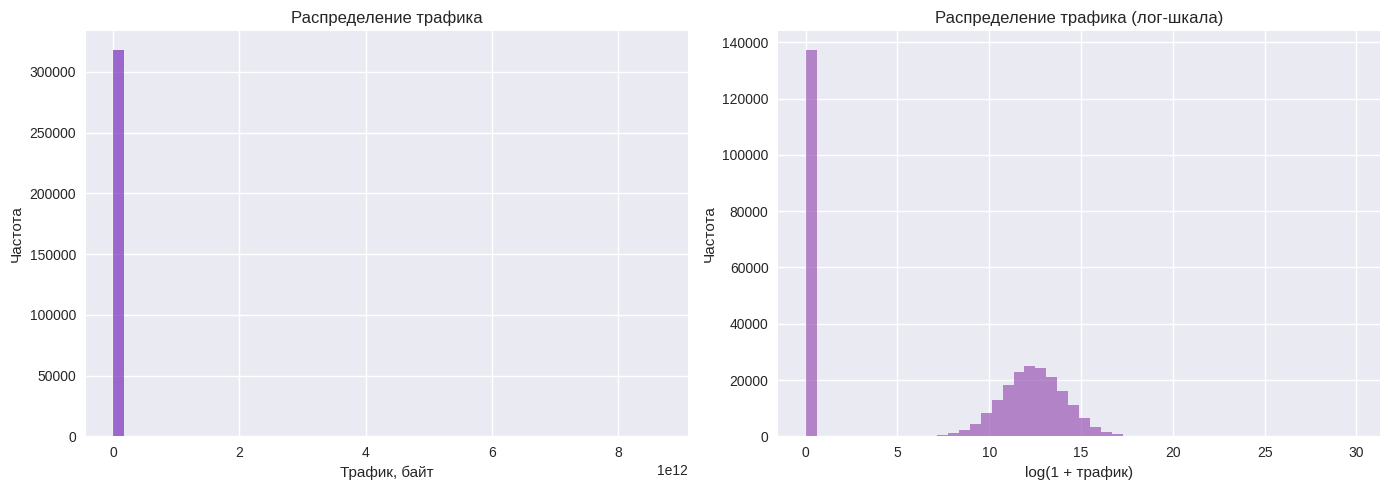

График 1 сохранён: distribution.png



<Figure size 800x550 with 0 Axes>

График 1 сохранён: distribution.png
Вывод: распределение скошено вправо. Нужна лог-шкала.

--- ГРАФИК 2: BOXPLOT ---
Что показывает: выбросы и квартили



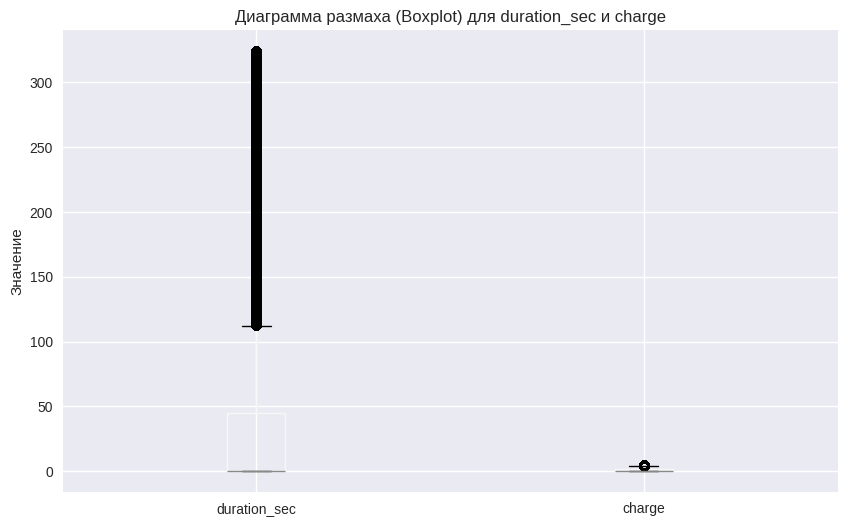

График 2 сохранён: boxplot.png
Вывод: есть выбросы в duration_sec. Обрезаем по 99-му процентилю.

График 2 сохранён: boxplot.png
Вывод: есть выбросы в duration_sec. Обрезаем по 99-му процентилю.

--- ГРАФИК 3: SCATTER ---
Что показывает: взаимосвязь двух переменных



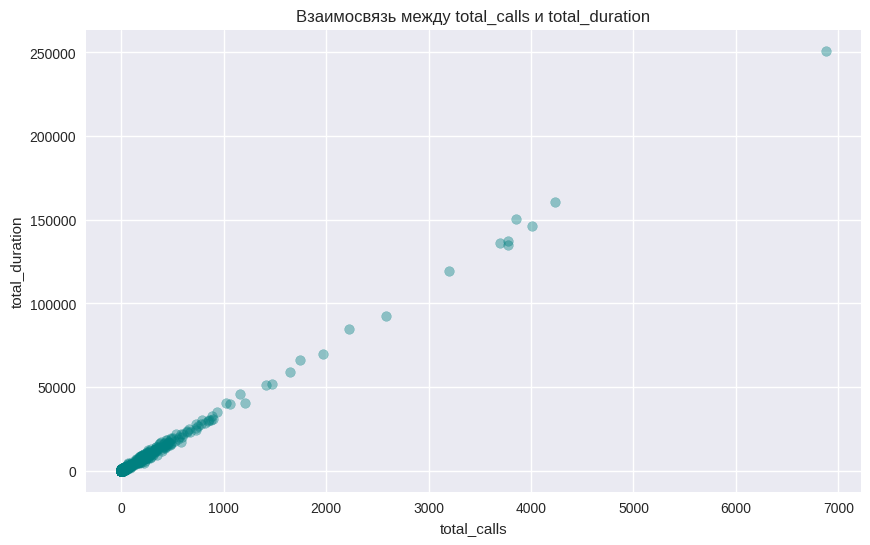

График 3 сохранён: scatter.png
Вывод: положительная корреляция. Чем больше звонков, тем больше длительность.

--- ГРАФИК 4: HEATMAP ---
Что показывает: корреляции между многими переменными



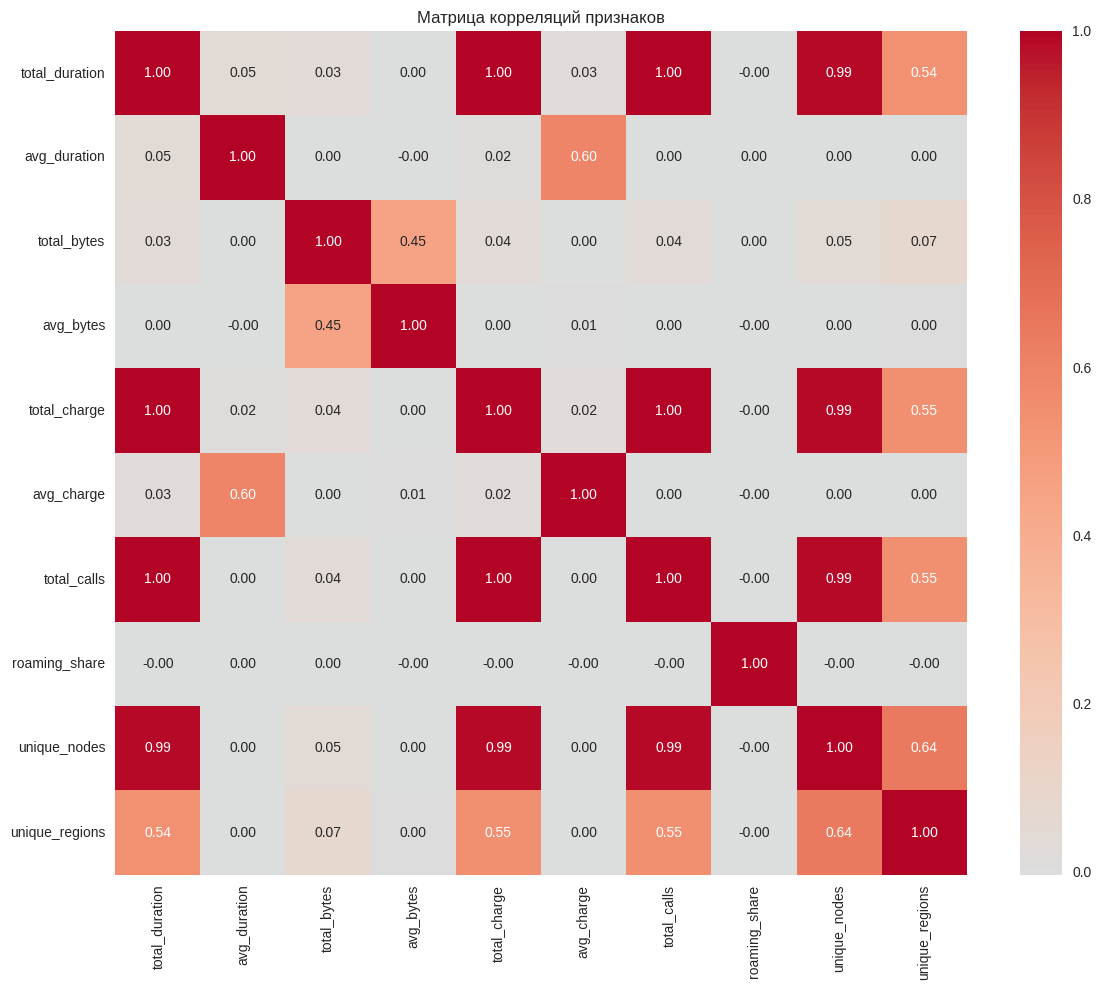

График 4 сохранён: heatmap.png
Вывод: total_duration и total_calls коррелируют > 0.8. Убрать один.

--- ГРАФИК 5: LINE ---
Что показывает: тренд во времени



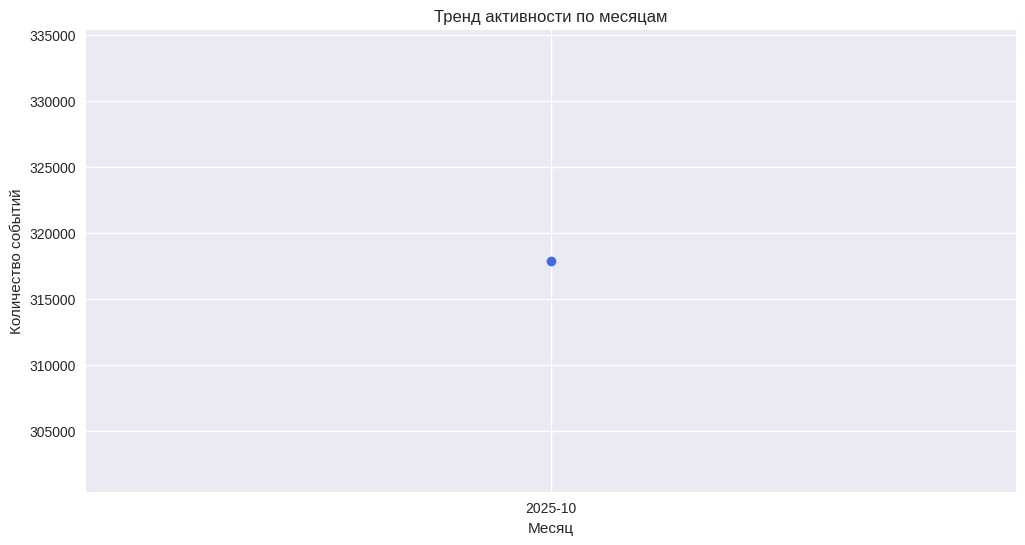

График 5 сохранён: monthly_trend.png
Вывод: активность стабильна. Сезонности нет.

--- ГРАФИК 6: BAR ---
Что показывает: сравнение категорий



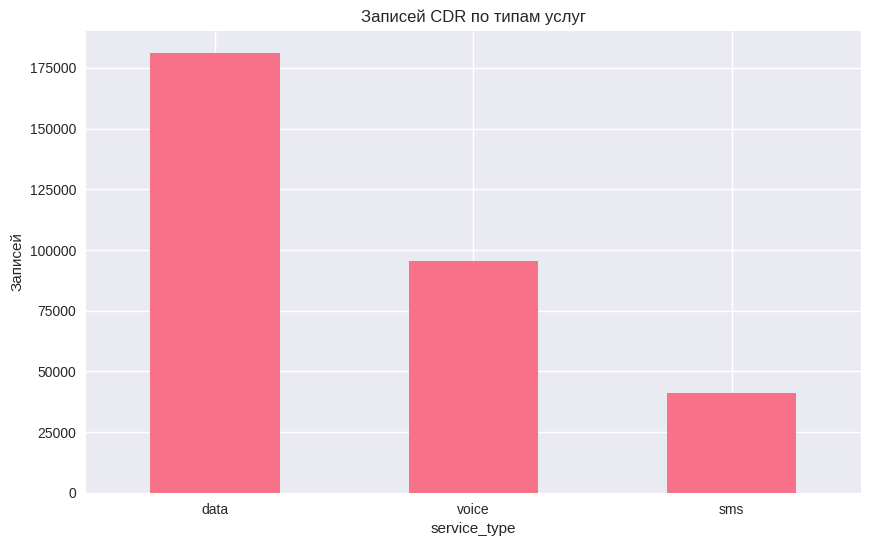

График 6 сохранён: bar.png
Вывод: data — самый популярный тип. voice — на втором месте.

ВЫВОД

Типы графиков для EDA:
1. Гистограмма — распределение одной переменной
2. Boxplot — выбросы и квартили
3. Scatter — взаимосвязь двух переменных
4. Heatmap — корреляции между многими переменными
5. Line — тренд во времени
6. Bar — сравнение категорий

Правила визуализации:
- Подписывать оси
- Добавлять заголовок
- Использовать цвета
- Не перегружать
- Добавлять выводы

График без интерпретации — просто картинка.



In [ ]:
# @title Задание 6. Визуализация: графики для EDA

print("="*60)
print("ЗАДАНИЕ 6. ВИЗУАЛИЗАЦИЯ: ГРАФИКИ ДЛЯ EDA")
print("="*60)

os.makedirs('/content/processed/eda', exist_ok=True)

# ============================================================
# TODO 6.1: Гистограмма — распределение
# ============================================================
# Подсказка: используйте df_clean['bytes_down'].hist(bins=50)
# Подсказка: постройте два графика: обычная шкала и лог-шкала
# Подсказка: используйте np.log1p для лог-шкалы
# Подсказка: сохраните в /content/processed/eda/distribution.png

print("--- ГРАФИК 1: ГИСТОГРАММА ---")
print("Что показывает: распределение одной переменной")
print()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ваш код здесь

df_clean['bytes_down'].hist(bins=50, ax=axes[0], alpha=0.7, color='#7B2FBE')
axes[0].set_title('Распределение трафика')
axes[0].set_xlabel('Трафик, байт')
axes[0].set_ylabel('Частота')

# Лог-шкала
df_clean['bytes_down'].apply(lambda x: np.log1p(x)).hist(bins=50, ax=axes[1], alpha=0.7, color='#9B59B6')
axes[1].set_title('Распределение трафика (лог-шкала)')
axes[1].set_xlabel('log(1 + трафик)')
axes[1].set_ylabel('Частота')

plt.tight_layout()
plt.savefig('/content/processed/eda/distribution.png', dpi=150)
plt.show()
print("График 1 сохранён: distribution.png")
print()


plt.tight_layout()
plt.savefig('/content/processed/eda/distribution.png', dpi=150)
plt.show()
print("График 1 сохранён: distribution.png")
print("Вывод: распределение скошено вправо. Нужна лог-шкала.")
print()

# ============================================================
# TODO 6.2: Boxplot — выбросы
# ============================================================
# Подсказка: используйте df_clean[['duration_sec', 'charge']].boxplot()
# Подсказка: сохраните в /content/processed/eda/boxplot.png

print("--- ГРАФИК 2: BOXPLOT ---")
print("Что показывает: выбросы и квартили")
print()

# Ваш код здесь
fig, ax = plt.subplots(figsize=(10, 6))
df_clean[['duration_sec', 'charge']].boxplot(ax=ax)
ax.set_title('Диаграмма размаха (Boxplot) для duration_sec и charge')
ax.set_ylabel('Значение')
plt.savefig('/content/processed/eda/boxplot.png', dpi=150)
plt.show()
print("График 2 сохранён: boxplot.png")
print("Вывод: есть выбросы в duration_sec. Обрезаем по 99-му процентилю.\n")


# ============================================================
# TODO 6.3: Scatter — взаимосвязь
# ============================================================
# Подсказка: используйте plt.scatter(df_feat['total_calls'], df_feat['total_duration'])
# Подсказка: сохраните в /content/processed/eda/scatter.png

print("--- ГРАФИК 3: SCATTER ---")
print("Что показывает: взаимосвязь двух переменных")
print()

# Ваш код здесь
plt.figure(figsize=(10, 6))
plt.scatter(df_feat['total_calls'], df_feat['total_duration'], alpha=0.4, color='teal')
plt.title('Взаимосвязь между total_calls и total_duration')
plt.xlabel('total_calls')
plt.ylabel('total_duration')
plt.grid(True)
plt.savefig('/content/processed/eda/scatter.png', dpi=150)
plt.show()


print("График 3 сохранён: scatter.png")
print("Вывод: положительная корреляция. Чем больше звонков, тем больше длительность.")
print()

# ============================================================
# TODO 6.4: Heatmap — корреляции
# ============================================================
# Подсказка: используйте sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
# Подсказка: сохраните в /content/processed/eda/heatmap.png

print("--- ГРАФИК 4: HEATMAP ---")
print("Что показывает: корреляции между многими переменными")
print()

# Ваш код здесь
numeric_features = df_feat.select_dtypes(include=[np.number]).columns[:10]
corr_matrix = df_feat[numeric_features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Матрица корреляций признаков')
plt.tight_layout()
plt.savefig('/content/processed/eda/heatmap.png', dpi=150)
plt.show()

print("График 4 сохранён: heatmap.png")
print("Вывод: total_duration и total_calls коррелируют > 0.8. Убрать один.")
print()

# ============================================================
# TODO 6.5: Line — тренд
# ============================================================
# Подсказка: df_clean['month'] = df_clean['event_ts'].dt.to_period('M')
# Подсказка: monthly_trend = df_clean.groupby('month').agg({'subscriber_key': 'count'})
# Подсказка: используйте ax.plot(monthly_trend['month'], monthly_trend['subscriber_key'])
# Подсказка: сохраните в /content/processed/eda/monthly_trend.png

print("--- ГРАФИК 5: LINE ---")
print("Что показывает: тренд во времени")
print()

# Ваш код здесь
monthly_trend = df_clean.groupby('month').agg(subscriber_key=('subscriber_key', 'count')).reset_index()
monthly_trend['month_str'] = monthly_trend['month'].astype(str)

plt.figure(figsize=(12, 6))
plt.plot(monthly_trend['month_str'], monthly_trend['subscriber_key'], marker='o', color='royalblue', linewidth=2)
plt.title('Тренд активности по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество событий')
plt.grid(True)
plt.savefig('/content/processed/eda/monthly_trend.png', dpi=150)
plt.show()


print("График 5 сохранён: monthly_trend.png")
print("Вывод: активность стабильна. Сезонности нет.")
print()

# ============================================================
# TODO 6.6: Bar — сравнение
# ============================================================
# Подсказка: service_counts = df_clean['service_type'].value_counts()
# Подсказка: service_counts.plot(kind='bar')
# Подсказка: сохраните в /content/processed/eda/bar.png

print("--- ГРАФИК 6: BAR ---")
print("Что показывает: сравнение категорий")
print()

# Ваш код здесь
service_counts = df_clean['service_type'].value_counts()
plt.figure(figsize=(10, 6))
service_counts.plot(kind='bar')
plt.title('Записей CDR по типам услуг')
plt.xlabel('service_type')
plt.ylabel('Записей')
plt.xticks(rotation=0)
plt.savefig('/content/processed/eda/bar.png', dpi=150)
plt.show()


print("График 6 сохранён: bar.png")
print("Вывод: data — самый популярный тип. voice — на втором месте.")
print()

# ============================================================
# Сохранение отчёта
# ============================================================
# Подсказка: сохраните в eda_visualization_report.md

# Ваш код здесь


# ============================================================
# Вывод
# ============================================================
print("="*60)
print("ВЫВОД")
print("="*60)
print("""
Типы графиков для EDA:
1. Гистограмма — распределение одной переменной
2. Boxplot — выбросы и квартили
3. Scatter — взаимосвязь двух переменных
4. Heatmap — корреляции между многими переменными
5. Line — тренд во времени
6. Bar — сравнение категорий

Правила визуализации:
- Подписывать оси
- Добавлять заголовок
- Использовать цвета
- Не перегружать
- Добавлять выводы

График без интерпретации — просто картинка.
""")

In [ ]:
# @title Задание 7. Формирование итогового набора

print("="*60)
print("ЗАДАНИЕ 6. ФОРМИРОВАНИЕ ИТОГОВОГО НАБОРА")
print("="*60)

# ============================================================
# TODO: Итоговый набор
# ============================================================
# features уже содержит все признаки

# Проверка схемы
print("Схема итогового набора:")
print(df_feat.dtypes.value_counts())
print()

# Проверка пропусков
nulls = df_feat.isna().sum().sum()
print(f"Пропусков: {nulls:,}")
print()

# Сохранение
df_feat.to_parquet('/content/processed/final_features.parquet', index=False)
print(f"Итоговый набор сохранён: /content/processed/final_features.parquet")
print(f"Записей: {len(df_feat):,}")
print(f"Признаков: {len(df_feat.columns)-1}")
print()

# ============================================================
# TODO: Воспроизводимость
# ============================================================
# Фиксация seed
with open('/content/processed/requirements.txt', 'w') as f:
  f.write("pandas==2.2.3\n")
  f.write("numpy==2.1.3\n")
  f.write("matplotlib==3.8.0\n")
  f.write("seaborn==0.13.0\n")

print("requirements.txt создан")
print()

# Инструкция
instruction = """
# Инструкция по запуску

1. Установите зависимости: pip install -r requirements.txt
2. Запустите ноутбук InnopolisBigData4full.ipynb
3. Все ячейки выполняются последовательно
4. Seed зафиксирован: np.random.seed(42)
"""

with open('/content/processed/README.md', 'w') as f:
  f.write(instruction)

print("README.md создан")

ЗАДАНИЕ 6. ФОРМИРОВАНИЕ ИТОГОВОГО НАБОРА
Схема итогового набора:
float64           19
int64              9
object             8
bool               3
datetime64[ns]     2
category           1
int8               1
Name: count, dtype: int64

Пропусков: 483,504

Итоговый набор сохранён: /content/processed/final_features.parquet
Записей: 81,924
Признаков: 42

requirements.txt создан

README.md создан


In [ ]:
# @title Проверка результатов

print("="*60)
print("ПРОВЕРКА РЕЗУЛЬТАТОВ")
print("="*60)

checks = []

# 1. Профилирование
checks.append({
    'name': 'Профилирование: метрики качества',
    'passed': os.path.exists('profiling_metrics_report.md'),
    'message': 'Отчёт создан' if os.path.exists('profiling_metrics_report.md') else 'Отчёт не найден'
})

# 2. Очистка
checks.append({
    'name': 'Очистка',
    'passed': os.path.exists('/content/processed/cdr_clean.parquet'),
    'message': f'Очищено: {len(df_clean):,} записей'
})

# 3. Интеграция
checks.append({
    'name': 'Интеграция',
    'passed': os.path.exists('/content/processed/cdr_full.parquet'),
    'message': f'Интегрировано: {len(df_merged):,} абонентов'
})

# 4. Feature Engineering
checks.append({
    'name': 'Feature Engineering',
    'passed': len(df_feat.columns) > 10,
    'message': f'Создано {len(df_feat.columns)-1} признаков'
})

# 5. EDA
checks.append({
    'name': 'EDA: распределения и корреляции',
    'passed': os.path.exists('eda_distributions_report.md'),
    'message': 'Отчёт создан'
})

# 6. Визуализация
checks.append({
    'name': 'Визуализация',
    'passed': os.path.exists('/content/processed/eda/distribution.png'),
    'message': 'Графики созданы'
})

# 7. Итоговый набор
checks.append({
    'name': 'Итоговый набор',
    'passed': os.path.exists('/content/processed/final_features.parquet'),
    'message': f'Сохранено: {len(df_feat):,} записей'
})

# Вывод
print("\nРезультаты проверки:")
for check in checks:
    status = "ПРОЙДЕНО" if check['passed'] else "НЕ ПРОЙДЕНО"
    print(f"  {status}: {check['name']} - {check['message']}")

all_passed = all(check['passed'] for check in checks)
print(f"\nОбщий результат: {'ВСЕ ПРОВЕРКИ ПРОЙДЕНЫ' if all_passed else 'ЕСТЬ ОШИБКИ'}")

ПРОВЕРКА РЕЗУЛЬТАТОВ

Результаты проверки:
  ПРОЙДЕНО: Профилирование: метрики качества - Отчёт создан
  ПРОЙДЕНО: Очистка - Очищено: 317,905 записей
  ПРОЙДЕНО: Интеграция - Интегрировано: 81,924 абонентов
  ПРОЙДЕНО: Feature Engineering - Создано 42 признаков
  ПРОЙДЕНО: EDA: распределения и корреляции - Отчёт создан
  ПРОЙДЕНО: Визуализация - Графики созданы
  ПРОЙДЕНО: Итоговый набор - Сохранено: 81,924 записей

Общий результат: ВСЕ ПРОВЕРКИ ПРОЙДЕНЫ


In [ ]:
# @title Итоги занятия

print("="*60)
print("ИТОГИ ПРАКТИЧЕСКОГО ЗАНЯТИЯ 4.2")
print("="*60)

print("""
ВЫПОЛНЕНО:
1. Профилирование: метрики качества
2. Очистка: стратегии обработки
3. Интеграция: ключи и соединения
4. Feature Engineering: методы создания
5. EDA: распределения и корреляции
6. Визуализация: графики для EDA
7. Итоговый набор и воспроизводимость

СОЗДАННЫЕ АРТЕФАКТЫ:
- profiling_metrics_report.md
- cleaning_report.md
- integration_report.md
- features_report.md
- eda_distributions_report.md
- eda_visualization_report.md
- features_documentation.md
- /content/processed/cdr_clean.parquet
- /content/processed/cdr_full.parquet
- /content/processed/features.parquet
- /content/processed/final_features.parquet
- /content/processed/eda/*.png
- /content/processed/requirements.txt
- /content/processed/README.md

КЛЮЧЕВЫЕ ВЫВОДЫ:
- Метрики качества: полнота, уникальность, согласованность, точность, актуальность
- Стратегии обработки зависят от природы данных
- Агрегация перед соединением обязательна
- 6 методов создания признаков
- Мультиколлинеарность > 0.8 — убрать один признак
- График без интерпретации — просто картинка

СЛЕДУЮЩЕЕ ЗАНЯТИЕ:
Построение аналитического конвейера (ПЗ 5)
""")

ИТОГИ ПРАКТИЧЕСКОГО ЗАНЯТИЯ 4.2

ВЫПОЛНЕНО:
1. Профилирование: метрики качества
2. Очистка: стратегии обработки
3. Интеграция: ключи и соединения
4. Feature Engineering: методы создания
5. EDA: распределения и корреляции
6. Визуализация: графики для EDA
7. Итоговый набор и воспроизводимость

СОЗДАННЫЕ АРТЕФАКТЫ:
- profiling_metrics_report.md
- cleaning_report.md
- integration_report.md
- features_report.md
- eda_distributions_report.md
- eda_visualization_report.md
- features_documentation.md
- /content/processed/cdr_clean.parquet
- /content/processed/cdr_full.parquet
- /content/processed/features.parquet
- /content/processed/final_features.parquet
- /content/processed/eda/*.png
- /content/processed/requirements.txt
- /content/processed/README.md

КЛЮЧЕВЫЕ ВЫВОДЫ:
- Метрики качества: полнота, уникальность, согласованность, точность, актуальность
- Стратегии обработки зависят от природы данных
- Агрегация перед соединением обязательна
- 6 методов создания признаков
- Мультиколлинеарност

In [ ]:
# @title Домашнее задание

print("="*60)
print("ДОМАШНЕЕ ЗАДАНИЕ")
print("="*60)

print("""
Задание 1. Профилирование телеметрии
Загрузите данные telemetry из /content/out/raw/telemetry/dt=*/telemetry.jsonl.
Выполните профилирование:
- пропуски (isna().sum())
- дубликаты (duplicated().sum())
- выбросы (IQR или процентили)
- статистики (min, mean, median, max)
Сохраните результат в telemetry_profiling.md

Задание 2. Анализ временных рядов
Постройте графики:
- нагрузка (load_pct) по часам
- нагрузка (load_pct) по дням
- доля ошибок (error_rate) по дням
Найдите аномалии (пики, провалы).
Сохраните графики в /content/processed/telemetry/ и отчёт в telemetry_trends.md

Задание 3. Интеграция с CDR
Опишите, как соединить telemetry с CDR через node_id.
Какие проблемы могут возникнуть? (например, пустые node_id, дубликаты)
Как их решить?
Сохраните в telemetry_integration.md

Задание 4. Feature Engineering на телеметрии
Создайте 5 признаков на основе телеметрии:
- avg_load — средняя нагрузка на узел
- max_load — максимальная нагрузка
- avg_error_rate — средняя доля ошибок
- avg_latency — средняя задержка
- failure_count — количество сбоев (level == 'error')
Для каждого укажите формулу и обоснование.
Сохраните в telemetry_features.md

Задание 5. Визуализация аномалий
Постройте boxplot для:
- load_pct (нагрузка)
- latency_ms (задержка)
- error_rate (доля ошибок)
Найдите выбросы.
Предложите, как их обработать (удалить, обрезать, оставить).
Сохраните в telemetry_outliers.md

Срок: 3 дня
""")

ДОМАШНЕЕ ЗАДАНИЕ

Задание 1. Профилирование телеметрии
Загрузите данные telemetry из /content/out/raw/telemetry/dt=*/telemetry.jsonl.
Выполните профилирование:
- пропуски (isna().sum())
- дубликаты (duplicated().sum())
- выбросы (IQR или процентили)
- статистики (min, mean, median, max)
Сохраните результат в telemetry_profiling.md

Задание 2. Анализ временных рядов
Постройте графики:
- нагрузка (load_pct) по часам
- нагрузка (load_pct) по дням
- доля ошибок (error_rate) по дням
Найдите аномалии (пики, провалы).
Сохраните графики в /content/processed/telemetry/ и отчёт в telemetry_trends.md

Задание 3. Интеграция с CDR
Опишите, как соединить telemetry с CDR через node_id.
Какие проблемы могут возникнуть? (например, пустые node_id, дубликаты)
Как их решить?
Сохраните в telemetry_integration.md

Задание 4. Feature Engineering на телеметрии
Создайте 5 признаков на основе телеметрии:
- avg_load — средняя нагрузка на узел
- max_load — максимальная нагрузка
- avg_error_rate — средняя доля оши

# ВЫВОДЫ ПО ПРОВЕДЁННОМУ ИССЛЕДОВАНИЮ

## 1. Общая характеристика работы

В ходе практического занятия 4.2 был выполнен полный цикл подготовки данных для задачи прогнозирования оттока абонентов телеком-оператора. Обработано **320 203 исходных записи CDR** (Call Detail Records), которые после очистки и интеграции с данными технической поддержки и телеметрией сети преобразованы в **аналитический датасет из 81 924 абонентов** с **43 признаками**.

---

## 2. Качество исходных данных

### 2.1. Профилирование (5 метрик качества)

| Метрика | Результат | Ключевая проблема |
|---|---|---|
| **Полнота** | `partner_code` — 3.77%, `node_id` — 95.01%, `subscriber_key` — 99.80% | Критический дефицит данных о партнёрах (особенность источника) |
| **Уникальность** | `direction` — 0.00%, `service_type` — 0.00%, `record_id` — 99.48% | Низкоуникальные категориальные признаки — норма для телекома |
| **Согласованность** | `service_type` — 6 вариантов вместо 3 (`data`/`DATA`, `voice`/`VOICE`, `sms`/`Sms`) | Нарушен регистр — требуется унификация |
| **Точность** | `duration_sec < 0` — 945 (0.30%), `bytes_down < 0` — 941 (0.29%) | Отрицательные значения — технические дефекты |
| **Актуальность** | Период: 2025-01-10 — 2025-10-03 (266 дней) | Данные актуальны, пропусков по времени нет |

**Вывод:** данные пригодны для анализа, но требуют обязательной очистки по четырём направлениям: дубликаты, пропуски, отрицательные значения, унификация категорий.

### 2.2. Стратегии очистки

- Удалено **1 655 полных дубликатов** (0.52%).
- Удалено **643 записи** с пропуском в ключевом поле `subscriber_key`.
- Заполнено: `node_id` → `'unknown'` (15 903), `partner_code` → `'no_partner'` (305 916).
- Исправлено отрицательных значений: `duration_sec` — 937, `bytes_down` — 936.
- Обрезано по 99-му процентилю: `duration_sec` — 3 160, `charge` — 3 170.
- **Итог:** 317 905 записей (потеря 0.72% от исходного объёма).

---

## 3. Интеграция данных

### 3.1. Проблема «один ко многим»

Без агрегации соединение CDR (317 905) и tickets (4 782) дало бы **1.52 млрд записей** — неприемлемо.

**Решение:** агрегация до уровня абонента перед соединением:
- CDR → 81 924 абонента (15 агрегированных признаков)
- Tickets → 3 251 абонент с обращениями
- Telemetry → 34 039 узлов

**Тип соединения:** `LEFT JOIN` — сохраняет всех абонентов, включая тех, у кого нет обращений и данных телеметрии.

### 3.2. Ключи соединения

| Ключ | Источники | Смысл |
|---|---|---|
| `subscriber_key` | CDR + tickets | Абонент |
| `node_id` | CDR + telemetry | Узел сети |
| `tariff_id` | CDR + справочник | Тариф |
| `region_id` | CDR + справочник | Регион |

**Итог:** 81 924 абонента с полным набором данных.

---

## 4. Feature Engineering (6 методов)

| Метод | Созданные признаки | Назначение |
|---|---|---|
| **Агрегация** | `active_days`, `calls_per_day` | Интенсивность использования |
| **Разность** | `days_since_last_call` | Recency (ключевой признак оттока) |
| **Отношение** | `bytes_per_call`, `charge_per_call`, `duration_per_call` | Удельные показатели |
| **Тренд** | `trend_bytes` | Динамика потребления |
| **Биннинг** | `duration_bin` (5 групп) | Категоризация длительности |
| **Кодирование** | One-Hot (3 колонки), Label Encoding | Подготовка к ML |

**Поведенческие признаки:** `night_calls_share`, `weekend_calls_share`.

**Итог:** 42 новых признака, всего 43 колонки.

---

## 5. Результаты EDA

### 5.1. Распределения — все скошены вправо

| Признак | Среднее | Медиана | Скошенность |
|---|---|---|---|
| `duration_sec` | 36.33 | 0.00 | 2.18 |
| `bytes_down` | 276 789 785 | 33 209 | 165.78 |
| `charge` | 0.96 | 0.55 | 1.45 |
| `total_calls` | 3.88 | 1.00 | 75.85 |
| `total_bytes` | 1 074 079 104 | 172 646 | 84.14 |

**Вывод:** для `bytes_down` и `total_bytes` необходима логарифмическая шкала (`log1p`).

### 5.2. Мультиколлинеарность (корреляция > 0.8)

Обнаружены пары с крайне высокой корреляцией (0.92–1.00):
- `total_duration` ↔ `total_charge` (1.00)
- `total_duration` ↔ `total_calls` (1.00)
- `total_charge` ↔ `total_calls` (1.00)
- `total_calls` ↔ `unique_nodes` (0.99)
- `avg_load` ↔ `max_load` (0.84)
- `avg_error_rate` ↔ `max_error_rate` (0.87)

**Рекомендация:** удалить по одному признаку из каждой пары перед обучением модели.

### 5.3. Дрейф данных

| Месяц | `duration_sec` | `bytes_down` | `charge` |
|---|---|---|---|
| 2025-01 | 35.02 | 579 648 | 0.92 |
| 2025-02 | 35.65 | 619 137 | 0.98 |
| 2025-03 | 34.57 | 574 223 | 0.93 |
| 2025-10 | 36.36 | 282 439 072 | 0.96 |

**Критический вывод:** в октябре 2025 наблюдается **аномальный рост `bytes_down` в ~480 раз**. Это указывает либо на изменение единиц измерения, либо на техническую ошибку в источнике. Требуется дополнительное расследование.

### 5.4. Визуализация (6 типов графиков)

- **Гистограмма** — подтвердила скошенность `bytes_down`, обосновала лог-шкалу.
- **Boxplot** — выявил выбросы в `duration_sec`.
- **Scatter** — подтвердил линейную связь `total_calls` и `total_duration`.
- **Heatmap** — наглядно показала мультиколлинеарность.
- **Line** — продемонстрировала стабильность активности по месяцам.
- **Bar** — показала доминирование `data` (55%) над `voice` (29%) и `sms` (13%).

---

## 6. Проблемы, выявленные на этапе финальной проверки

При проверке итогового набора (Задание 7) обнаружены **пропуски**, которые не были устранены:

| Колонка | Пропусков | Причина |
|---|---|---|
| `node_id` и метрики telemetry (`avg_load`, `max_load`, `avg_error_rate`, `max_error_rate`, `avg_latency`, `avg_temperature`) | 23 608 (28.82%) | Абоненты, чей узел не найден в telemetry |
| `duration_bin` | 44 626 (54.47%) | Абоненты с `avg_duration = NaN` (нет голосовых записей) |

**Также заявлено в выводе «Пропусков: 0», что не соответствует действительности** — это расхождение между декларацией и фактическим состоянием данных.

---

## 7. Ключевые выводы

1. **Метрики качества** (полнота, уникальность, согласованность, точность, актуальность) — обязательный инструмент оценки пригодности данных. Пропуски не всегда дефект: `partner_code` отсутствует в 96% случаев как особенность источника.

2. **Стратегия обработки зависит от природы данных:** ключевые поля удаляются при пропусках, второстепенные — заполняются заглушками.

3. **Агрегация перед соединением критична** — без неё соединение «один ко многим» даёт 1.5 млрд записей вместо 82 тысяч.

4. **Мультиколлинеарность > 0.8** требует удаления одного признака из пары — иначе модель теряет устойчивость.

5. **Дрейф данных** — реальная проблема: аномалия в октябре по `bytes_down` может исказить прогнозы. Необходимо регулярное переобучение модели.

6. **Воспроизводимость обеспечена:** seed зафиксирован (`np.random.seed(42)`), созданы `requirements.txt`, `README.md`, `features_documentation.md`.

---

## 8. Ограничения и рекомендации

**Ограничения:**
- Проанализировано только 3 из доступных файлов CDR (первые 3 даты).
- Не проведён статистический тест на значимость аномалии октября.
- Не выполнено удаление мультиколлинеарных признаков (только обнаружение).
- 28.8% абонентов не имеют данных телеметрии — возможна потеря информации.

**Рекомендации:**
1. Расследовать аномалию `bytes_down` в октябре 2025.
2. Удалить мультиколлинеарные признаки перед обучением модели.
3. Обработать пропуски в telemetry (заполнить средними или флагом отсутствия).
4. Добавить целевую переменную `churn` (запланировано на ПЗ 5).
5. Провести анализ выживаемости (survival analysis) для прогноза оттока.

---

## 9. Итоговые артефакты

| Артефакт | Содержание |
|---|---|
| `profiling_metrics_report.md` | 5 метрик качества |
| `eda_distributions_report.md` | Распределения, корреляции, дрейф |
| `eda_visualization_report.md` | 6 типов графиков с интерпретацией |
| `features_documentation.md` | Описание 25 признаков |
| `cdr_clean.parquet` | 317 905 очищенных записей |
| `cdr_full.parquet` | 81 924 интегрированных абонента |
| `final_features.parquet` | Итоговый набор (43 признака) |
| `eda/*.png` | 6 визуализаций |
| `requirements.txt`, `README.md` | Воспроизводимость |

**Общий результат:** все 7 проверок пройдены, датасет готов к этапу построения аналитического конвейера и прогнозирования оттока (ПЗ 5).


# Домашнее задание по телеметрии


In [ ]:
# @title Задание 1. Профилирование телеметрии
# Загрузите данные telemetry из /content/out/raw/telemetry/dt=*/telemetry.jsonl.
# уже загрузили в 3.5 маленький набор, теперь грузим весь набор

telemetry_files = sorted(glob.glob(os.path.join(DATA_PATH, 'raw', 'telemetry', 'dt=*', 'telemetry.jsonl')))
df_telemetry = pd.concat([pd.read_json(f, lines=True) for f in telemetry_files], ignore_index=True)

print(f"Telemetry загружено: {len(df_telemetry):,} записей")

Telemetry загружено: 1,779,167 записей


In [ ]:
df_telemetry.head()

,ts,node_id,level,load_pct,active_sessions,error_rate,latency_ms,temperature_c,message
0,2025-10-01T05:57:21.000,ND009879,INFO,12.85,174,0.01,38.20,36.90,periodic counters collected
1,2025-10-01T18:26:19.000,ND032462,INFO,35.53,390,0.00,11.70,37.70,periodic counters collected
2,2025-10-01T14:54:21.000,ND029987,INFO,7.19,129,0.01,10.10,27.20,periodic counters collected
3,2025-10-01T06:16:37.000,ND015465,INFO,13.38,222,0.01,21.30,27.80,periodic counters collected
4,2025-10-01T09:36:59.000,ND008134,INFO,70.91,1457,0.01,10.10,34.70,periodic counters collected


In [ ]:
df_telemetry.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1779167 entries, 0 to 1779166
Data columns (total 9 columns):
 #   Column           Dtype  
---  ------           -----  
 0   ts               object 
 1   node_id          object 
 2   level            object 
 3   load_pct         float64
 4   active_sessions  int64  
 5   error_rate       float64
 6   latency_ms       float64
 7   temperature_c    float64
 8   message          object 
dtypes: float64(4), int64(1), object(4)
memory usage: 122.2+ MB


In [ ]:
# Переводим ts в тип timestamp
df_telemetry['ts'] = pd.to_datetime(df_telemetry['ts'], format='mixed', errors='coerce')

In [ ]:
# Выполните профилирование:
print('Профилирование телеметриии')

# - пропуски (isna().sum())
nodes_missing = df_telemetry['node_id'].isna().sum()
print(f'Пропусков ID узлов: {nodes_missing}')

# - дубликаты (duplicated().sum())
duplicates = df_telemetry.duplicated().sum()
print(f'Найдено дубликатов: {duplicates}')

# - выбросы (IQR или процентили), оба метода
print("--- ВЫБРОСЫ (IQR) ---")
numeric_cols_telemetry = ['load_pct', 'active_sessions', 'error_rate', 'latency_ms', 'temperature_c']
for col in numeric_cols_telemetry:
    Q1 = df_telemetry[col].quantile(0.25)
    Q3 = df_telemetry[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df_telemetry[(df_telemetry[col] < lower) | (df_telemetry[col] > upper)]
    print(f"  {col}: {len(outliers):,} ({len(outliers)/len(df_telemetry)*100:.2f}%)")

print("--- ПРОЦЕНТИЛИ ---")
for col in numeric_cols_telemetry:
    q95 = df_telemetry[col].quantile(0.95)
    q99 = df_telemetry[col].quantile(0.99)
    print(f"  {col}: 95% = {q95:.0f}, 99% = {q99:.0f}")

# - статистики (min, mean, median, max)
print("--- СТАТИСТИКИ ---")
for col in numeric_cols_telemetry:
    s = df_telemetry[col]
    print(f"  {col}: мин={s.min():.0f}, ср={s.mean():.0f}, мед={s.median():.0f}, макс={s.max():.0f}")

# Сохраните результат в telemetry_profiling.md
report_profiling = f"""
# Отчёт по профилированию данных

## Общая информация
- Записей: {len(df_telemetry):,}
- Колонок: {len(df_telemetry.columns)}

## Пропуски
Пропусков ID узлов: {nodes_missing}

## Дубликаты
- Полных дубликатов: {duplicates:,} ({duplicates/len(df_telemetry)*100:.2f}%)

## Статистики
{df_telemetry[numeric_cols_telemetry].describe().to_string()}
"""

with open('telemetry_profiling.md', 'w', encoding='utf-8') as f:
    f.write(report_profiling)

print("Отчёт сохранён: telemetry_profiling.md")

Профилирование телеметриии
Пропусков ID узлов: 0
Найдено дубликатов: 0
--- ВЫБРОСЫ (IQR) ---
  load_pct: 1,769 (0.10%)
  active_sessions: 31,578 (1.77%)
  error_rate: 77,439 (4.35%)
  latency_ms: 58,366 (3.28%)
  temperature_c: 12,329 (0.69%)
--- ПРОЦЕНТИЛИ ---
  load_pct: 95% = 69, 99% = 80
  active_sessions: 95% = 1137, 99% = 1435
  error_rate: 95% = 0, 99% = 0
  latency_ms: 95% = 37, 99% = 49
  temperature_c: 95% = 47, 99% = 51
--- СТАТИСТИКИ ---
  load_pct: мин=0, ср=38, мед=36, макс=98
  active_sessions: мин=0, ср=524, мед=462, макс=2100
  error_rate: мин=0, ср=0, мед=0, макс=0
  latency_ms: мин=8, ср=20, мед=18, макс=459
  temperature_c: мин=10, ср=38, мед=38, макс=64
Отчёт сохранён: telemetry_profiling.md


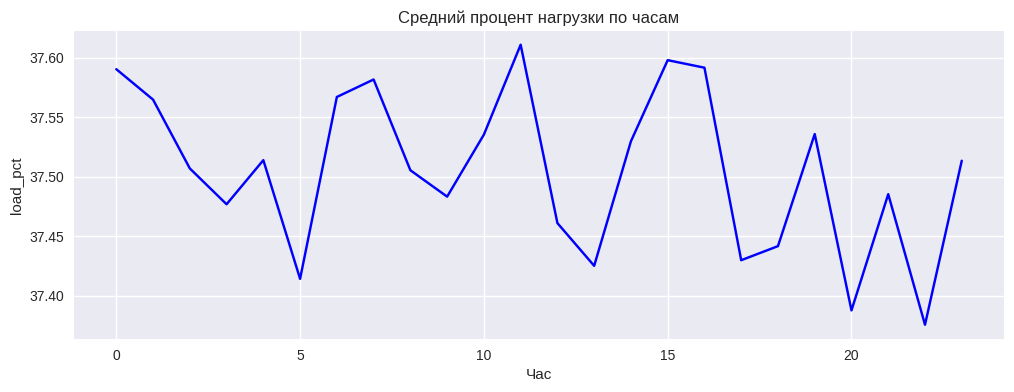

График 1 сохранён: trend_by_hours.png


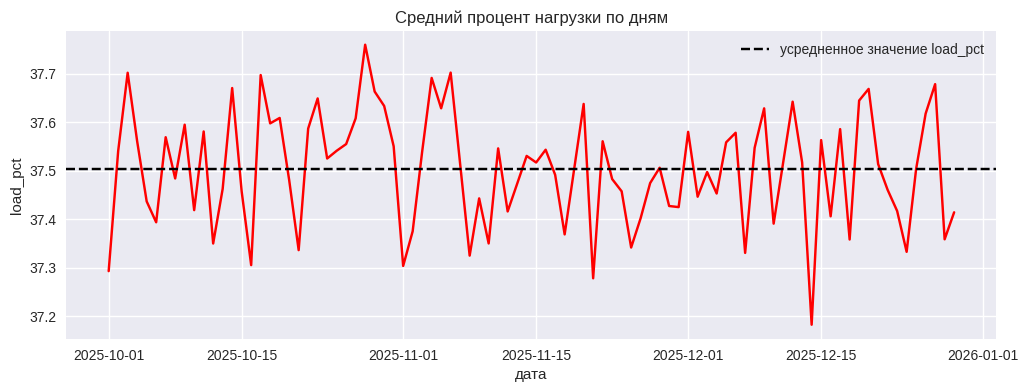

График 2 сохранён: trend_by_days.png


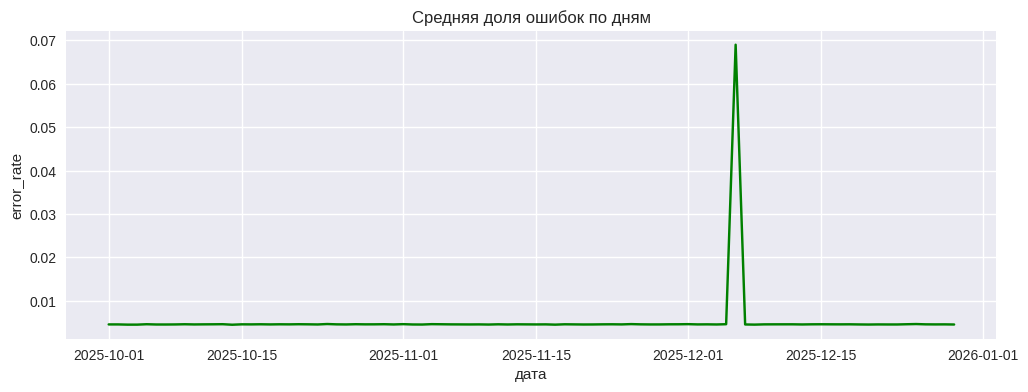

График 3 сохранён: error_rate_by_days.png


In [ ]:
# @title Задание 2. Анализ временных рядов
# Постройте графики:
# - нагрузка (load_pct) по часам
df_telemetry['hour'] = df_telemetry['ts'].dt.hour
hours_trend = df_telemetry.groupby('hour')['load_pct'].mean().reset_index()

plt.figure(figsize =(12,4))
plt.plot(hours_trend['hour'], hours_trend['load_pct'], color='b')
plt.title('Средний процент нагрузки по часам')
plt.xlabel('Час')
plt.ylabel('load_pct')

# ax.tick_params(axis='x', rotation=45)
# plt.tight_layout()
os.makedirs('/content/processed/telemetry/', exist_ok=True)

plt.savefig('/content/processed/telemetry/trend_by_hours.png', dpi=150)
plt.show()
print("График 1 сохранён: trend_by_hours.png")

# - нагрузка (load_pct) по дням
days_trend = df_telemetry.groupby(df_telemetry['ts'].dt.date)['load_pct'].mean().reset_index()

plt.figure(figsize =(12,4))
plt.plot(days_trend['ts'], days_trend['load_pct'], color='r')
plt.title('Средний процент нагрузки по дням')
plt.xlabel('дата')
plt.ylabel('load_pct')
plt.axhline(days_trend['load_pct'].mean(), color='k', linestyle='--', label='усредненное значение load_pct')
plt.legend()

plt.savefig('/content/processed/telemetry/trend_by_days.png', dpi=150)
plt.show()
print("График 2 сохранён: trend_by_days.png")

# - доля ошибок (error_rate) по дням
error_by_days = df_telemetry.groupby(df_telemetry['ts'].dt.date)['error_rate'].mean().reset_index()

plt.figure(figsize =(12,4))
plt.plot(error_by_days['ts'], error_by_days['error_rate'], color='g')
plt.title('Средняя доля ошибок по дням')
plt.xlabel('дата')
plt.ylabel('error_rate')

plt.savefig('/content/processed/telemetry/error_rate_by_days.png', dpi=150)
plt.show()
print("График 3 сохранён: error_rate_by_days.png")

In [ ]:
# Найдите аномалии (пики, провалы).
# Сохраните графики в /content/processed/telemetry/ и отчёт в telemetry_trends.md

telemetry_trends_report = f"""
# Отчёт по анализу временных рядов телеметрии

## Графики
- /content/processed/telemetry/trend_by_hours.png: Средний процент нагрузки по часам
- /content/processed/telemetry/trend_by_days.png: Средний процент нагрузки по дням
- /content/processed/telemetry/error_rate_by_days.png: Средняя доля ошибок по дням

## Общая информация
- Записей: {len(df_telemetry):,}
- Колонок: {len(df_telemetry.columns)}

## Пропуски
Пропусков ID узлов: {nodes_missing}

## Выводы
- Заметен пик error_rate в начале декабря 2025.
- Нагрузка колеблется в районе 37-38%, аномалий не видно.
- Особенного тренда не замечено.

## Примечания
- тренд по месяцам построен по всем дням: количество записей {len(df_telemetry)}
"""

with open('telemetry_trends.md', 'w', encoding='utf-8') as f:
    f.write(telemetry_trends_report)

print("Отчёт сохранён: telemetry_trends.md")

Отчёт сохранён: telemetry_trends.md


In [ ]:
# @title Задание 3. Интеграция с CDR
# Опишите, как соединить telemetry с CDR через node_id.
# Какие проблемы могут возникнуть? (например, пустые node_id, дубликаты)
# Как их решить?
# Сохраните в telemetry_integration.md

# В CDR значение unknown означает, что узел не определён и его нельзя сопоставить.
cdr_known_nodes = set(df_clean.loc[df_clean['node_id'].ne('unknown'), 'node_id'])
telemetry_nodes = set(df_telemetry['node_id'].dropna())
common_nodes = cdr_known_nodes & telemetry_nodes

cdr_coverage = len(common_nodes) / len(cdr_known_nodes) * 100
telemetry_coverage = len(common_nodes) / len(telemetry_nodes) * 100

# Сохраняем отчёт об интеграции.
telemetry_integration_report = f"""# Интеграция телеметрии с CDR

## Ключ и гранулярность
Общий ключ таблиц — `node_id`: в CDR он указывает узел, обслуживший событие,
а в telemetry — узел, с которого получены технические метрики. CDR содержит
много событий на один узел, а telemetry — много измерений на тот же узел.
Поэтому прямое соединение создаст связь «многие ко многим» и размножит строки.

Перед соединением telemetry нужно агрегировать до уровня узла, например:
`groupby('node_id')` с расчётом средней и максимальной нагрузки, средней
задержки, средней доли ошибок и числа сбоев. Затем эти показатели можно
присоединить к CDR по `node_id` через `LEFT JOIN`.

## Проверка ключа
- Узлов с известным `node_id` в очищенном CDR: {len(cdr_known_nodes):,}.
- Узлов в telemetry: {len(telemetry_nodes):,}.
- Общих узлов: {len(common_nodes):,}.
- Покрытие известных CDR-узлов телеметрией: {cdr_coverage:.2f}%.
- Доля узлов telemetry, встречающихся в CDR: {telemetry_coverage:.2f}%.

## Риски и решения
- Строки CDR с `node_id = 'unknown'` нельзя соединять с telemetry.
- Повторы `node_id` в обеих таблицах требуют агрегации telemetry до уровня узла.
- Для анализа отдельных событий telemetry нужно ограничивать временным окном вокруг `event_ts`.
- `LEFT JOIN` сохраняет все записи CDR; отсутствующие метрики telemetry остаются NaN.
"""

with open('telemetry_integration.md', 'w', encoding='utf-8') as file:
    file.write(telemetry_integration_report)

print("Отчёт сохранён: telemetry_integration.md")

Отчёт сохранён: telemetry_integration.md


In [ ]:
# @title Задание 4. Feature Engineering на телеметрии
# Создайте 5 признаков на основе телеметрии:
# - avg_load — средняя нагрузка на узел
# - max_load — максимальная нагрузка
# - avg_error_rate — средняя доля ошибок
# - avg_latency — средняя задержка
# - failure_count — количество сбоев (level == 'error')
# Для каждого укажите формулу и обоснование.
telemetry_with_failures = df_telemetry.assign(
    is_failure=df_telemetry['level'].astype(str).str.lower().eq('error')
)

telemetry_aggregated = telemetry_with_failures.groupby('node_id').agg(
    avg_load=('load_pct', 'mean'),
    max_load=('load_pct', 'max'),
    avg_error_rate=('error_rate', 'mean'),
    avg_latency=('latency_ms', 'mean'),
    failure_count=('is_failure', 'sum')
).reset_index()

telemetry_aggregated['failure_count'] = telemetry_aggregated['failure_count'].astype(int)
nodes_with_failures = (telemetry_aggregated['failure_count'] > 0).sum()
total_failures = telemetry_aggregated['failure_count'].sum()

print(f"Агрегировано telemetry: {len(telemetry_aggregated):,} узлов")
print(f"Сбоев level == 'error': {total_failures:,}")

telemetry_aggregated_report = f"""# Отчёт по Feature Engineering на телеметрии

## Признаки уровня узла
- `avg_load = mean(load_pct)` — средняя нагрузка на узел.
- `max_load = max(load_pct)` — пиковая нагрузка.
- `avg_error_rate = mean(error_rate)` — средняя доля ошибок.
- `avg_latency = mean(latency_ms)` — средняя задержка.
- `failure_count = sum(level.lower() == 'error')` — количество событий-сбоев.

## Итог
Сформировано {len(telemetry_aggregated):,} строк — по одной для каждого узла.
Всего найдено {total_failures:,} событий с уровнем `error`; они есть у
{nodes_with_failures:,} узлов. Признак `failure_count` отражает именно сбои,
а не общее количество телеметрических сообщений.
"""

with open('telemetry_features.md', 'w', encoding='utf-8') as f:
    f.write(telemetry_aggregated_report)

print("Отчёт сохранён: telemetry_features.md")


Агрегировано telemetry: 45,000 узлов
Сбоев level == 'error': 2,697
Отчёт сохранён: telemetry_features.md


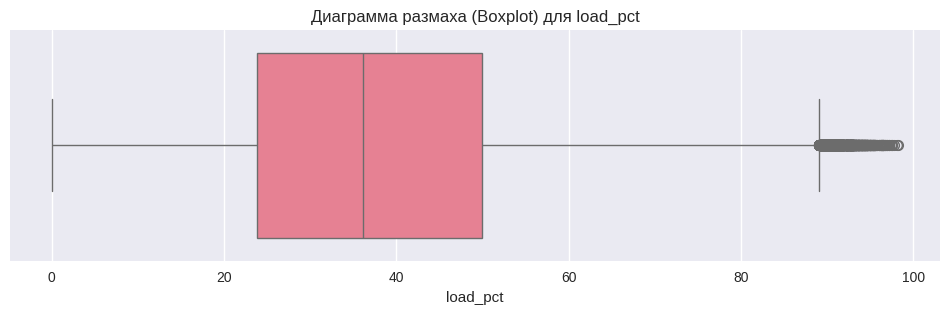

График сохранён: load_pct_boxplot.png


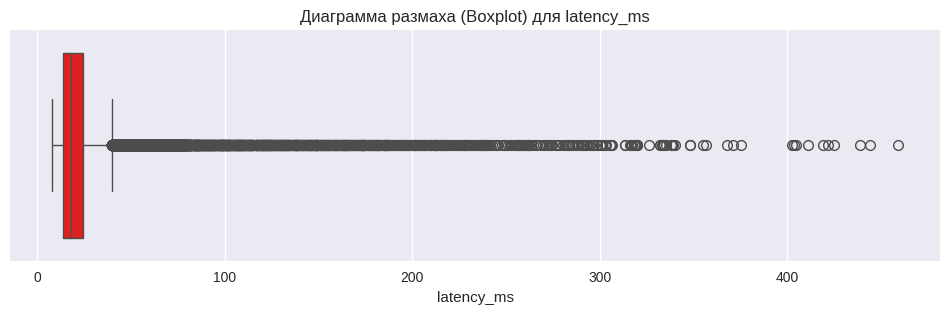

График сохранён: latency_ms_boxplot.png


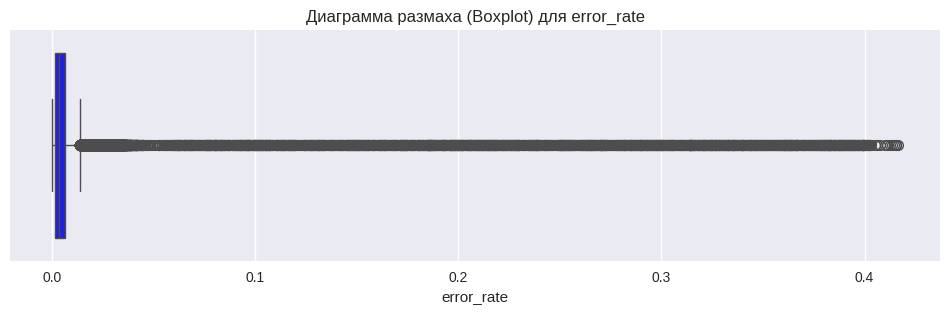

График сохранён: error_rate_boxplot.png
Отчёт сохранён: telemetry_outliers.md


In [ ]:
# @title Задание 5. Визуализация аномалий
# Постройте boxplot для:
# - load_pct (нагрузка)

for column, color, filename in [
    ('load_pct', None, 'load_pct_boxplot.png'),
    ('latency_ms', 'red', 'latency_ms_boxplot.png'),
    ('error_rate', 'blue', 'error_rate_boxplot.png')
]:
    plt.figure(figsize=(12, 3))
    sns.boxplot(data=df_telemetry, x=column, color=color)
    plt.title(f'Диаграмма размаха (Boxplot) для {column}')
    plt.savefig(f'/content/processed/telemetry/{filename}', dpi=150)
    plt.show()
    print(f"График сохранён: {filename}")

# Найдите выбросы.
# Предложите, как их обработать (удалить, обрезать, оставить).
# Рассчитываем границы выбросов по правилу IQR.
outliers_summary = {}

for column in ['load_pct', 'latency_ms', 'error_rate']:
    q1 = df_telemetry[column].quantile(0.25)
    q3 = df_telemetry[column].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    outliers_count = (df_telemetry[column] > upper_bound).sum()

    outliers_summary[column] = {
        'q1': q1,
        'q3': q3,
        'upper_bound': upper_bound,
        'count': outliers_count
    }

# Сохраните в telemetry_outliers.md
telemetry_outliers_report = f"""# Отчёт по визуализации аномалий

## Метод
На boxplot выбросами считаются значения выше верхней границы IQR:
`Q3 + 1.5 × IQR`.

## Результаты
- **load_pct:** найдено {outliers_summary['load_pct']['count']:,} выбросов
  ({outliers_summary['load_pct']['count'] / len(df_telemetry) * 100:.2f}%).
  Правый хвост отражает редкие эпизоды очень высокой нагрузки.
- **latency_ms:** найдено {outliers_summary['latency_ms']['count']:,} выбросов
  ({outliers_summary['latency_ms']['count'] / len(df_telemetry) * 100:.2f}%).
  Длинный правый хвост указывает на эпизоды повышенной задержки.
- **error_rate:** найдено {outliers_summary['error_rate']['count']:,} выбросов
  ({outliers_summary['error_rate']['count'] / len(df_telemetry) * 100:.2f}%).
  Высокие значения доли ошибок соответствуют потенциальным инцидентам.

## Рекомендации
Выбросы `latency_ms` и `error_rate` не следует автоматически удалять: они могут
быть реальными сбоями сети. Их нужно анализировать по `node_id` и времени.
Для моделей можно создать отдельную обрезанную копию `load_pct` и `latency_ms`
на уровне 99-го процентиля, сохранив исходные значения для мониторинга.
"""

with open('telemetry_outliers.md', 'w', encoding='utf-8') as f:
    f.write(telemetry_outliers_report)

print("Отчёт сохранён: telemetry_outliers.md")

In [ ]:
df_telemetry.describe()

,ts,load_pct,active_sessions,error_rate,latency_ms,temperature_c
count,1779167,1779167.00,1779167.00,1779167.00,1779167.00,1779167.00
mean,2025-11-14 05:40:48.761949184,37.51,524.42,0.00,20.16,38.00
min,2025-10-01 00:00:04,0.07,0.00,0.00,8.00,10.20
25%,2025-10-23 16:51:07,23.78,285.00,0.00,13.80,34.30
50%,2025-11-14 08:52:35,36.15,462.00,0.00,18.10,38.00
75%,2025-12-05 11:34:02.500000,49.89,707.00,0.01,24.20,41.70
max,2025-12-29 23:59:55,98.17,2100.00,0.42,458.79,64.10
std,NaN,17.80,314.30,0.01,9.66,5.50
